## 1. Введение

### Постановка задачи

При поиске медиаконтента пользователь нередко формулирует запросы в виде диалога, последовательно уточняя или изменяя свои предпочтения.

Например:

> **Пользователь:** Найди фильмы про путешествия во времени.
>
> **Пользователь:** А из девяностых?

Последняя реплика «А из девяностых?» не является самостоятельным поисковым запросом. Без истории диалога поисковая система не может однозначно восстановить предмет поиска.

В то же время простое объединение всех предыдущих реплик также не всегда корректно. Пользователь может отменять ограничения, менять жанр или тему, исключать ранее предложенные произведения и начинать новый поиск.

Для решения этой проблемы используется **контекстно-зависимое рефразирование запросов (conversational query rewriting)** — преобразование текущей реплики с учётом истории диалога в самостоятельную поисковую формулировку.

В приведённом примере результатом рефразирования будет:

> Фильмы про путешествия во времени из девяностых годов.

Такой запрос содержит необходимую информацию и может быть передан обычной поисковой системе без дополнительного доступа к истории диалога.

### Цель исследования

**Цель работы** — разработать и исследовать рефразер диалоговых запросов для поиска фильмов и мультфильмов, а также оценить влияние рефразирования на качество поисковой выдачи.

В рамках работы рассматриваются два взаимосвязанных вопроса:

1. Насколько корректно языковая модель восстанавливает актуальное поисковое намерение пользователя?
2. Улучшает ли использование рефразированных запросов релевантность результатов семантического поиска?

### Гипотеза

Основная гипотеза исследования состоит в том, что **восстановление контекста диалога в самостоятельном поисковом запросе повышает релевантность найденного медиаконтента** по сравнению с использованием последней реплики пользователя без истории.

При этом предполагается, что качество поиска зависит не только от корректности рефразирования, но и от возможностей самой поисковой системы.

### Задачи исследования

Для достижения поставленной цели необходимо:

1. Сформировать набор диалоговых сценариев, включающих различные операции над поисковыми ограничениями: добавление, замену, отмену, исключение и восстановление контекстных отсылок.
2. Реализовать рефразер на основе языковой модели и разработать базовую системную инструкцию.
3. Исследовать возможности улучшения рефразирования с помощью промпт-инжиниринга и провести сравнительную оценку полученных результатов.
4. Проверить выбранный рефразер на отложенной тестовой выборке.
5. Реализовать семантический поиск по русскоязычным описаниям фильмов и мультфильмов.
6. Сравнить релевантность поисковой выдачи для исходных, рефразированных и эталонных запросов.
7. Проанализировать выявленные ошибки и ограничения предложенного подхода.

### Методология

Для исследования подготовлен набор из **45 диалоговых сценариев**, разделённый на разработочную выборку из 35 примеров и отложенную тестовую выборку из 10 примеров.

В качестве рефразера используется модель **GigaChat-2**. Улучшение её работы осуществляется посредством изменения системных инструкций без дополнительного обучения модели.

Качество рефразирования оценивается по смысловой корректности: итоговый запрос должен быть понятен без истории диалога, сохранять актуальные ограничения и не добавлять необоснованные требования.

Для оценки влияния рефразирования на поиск используется модель эмбеддингов **`intfloat/multilingual-e5-small`** и библиотека **PyTorch**. Поиск выполняется по корпусу русскоязычных описаний медиаконтента на основе косинусного сходства векторных представлений.

Сравниваются три варианта запросов:

- **Original** — исходная реплика пользователя;
- **Rewritten** — результат разработанного рефразера;
- **Reference** — эталонная самостоятельная формулировка.

В качестве основной поисковой метрики используется **Precision@5** — доля релевантных документов среди пяти первых результатов поиска.

Релевантность оценивается с помощью ChatGPT на основе описаний найденных произведений. Для случаев с недостаточной информацией используется отдельная неопределённая оценка. Полученные результаты рассматриваются как предварительные и анализируются с учётом ограничений корпуса и процедуры оценивания.

### Структура работы

Работа состоит из следующих этапов:

- **Раздел 2.** Формирование и анализ набора диалоговых запросов.
- **Раздел 3.** Разработка рефразера, эксперименты с промптами и оценка смысловой корректности.
- **Раздел 4.** Реализация семантического поиска и исследование влияния рефразирования на релевантность выдачи.
- **Раздел 5.** Обобщение результатов, основные выводы и направления дальнейшего развития.


## 2. Подготовка данных

### 2.1. Формирование набора поисковых запросов

В качестве предметной области исследования выбран поиск фильмов и мультфильмов. Для оценки качества рефразирования сформирован датасет из 45 пользовательских запросов, включающий самостоятельные поисковые формулировки и реплики, зависящие от контекста предыдущего диалога.

Первоначальные 23 примера были составлены вручную на основе типичных сценариев взаимодействия пользователя с поисковой системой. Они охватывают уточнение требований, замену и снятие ограничений, исключение нежелательного контента, смену темы и поиск похожих произведений.

После анализа первоначального набора были выявлены недостаточно представленные сценарии: многошаговые диалоги, использование ответов поисковой системы, поиск по настроению и ситуации просмотра, а также самостоятельные запросы, не требующие преобразования.

Для устранения этих недостатков датасет был расширен на 22 синтетических примера, сгенерированных с помощью языковой модели. Генерация выполнялась по структурированной инструкции с заданным распределением сценариев, требованиями к естественности диалогов, сохранению пользовательского намерения и корректности эталонных формулировок.

При формировании набора основное внимание уделялось разнообразию поисковых намерений, языковых конструкций и способов использования контекста.

Полученные данные предназначены для дальнейшей проверки корректности рефразирования, сохранения актуальных ограничений и влияния преобразованных запросов на качество поиска медиаконтента

### 2.2. Структура и разметка датасета

Датасет хранится в формате JSON и содержит 45 записей. Каждая запись представляет отдельный сценарий поиска медиаконтента с учётом истории диалога.

Для каждого примера предусмотрены следующие поля:

| Поле | Описание |
|---|---|
| `id` | Уникальный идентификатор примера |
| `history` | История предыдущих реплик в хронологическом порядке с указанием роли (`user` или `assistant`) |
| `query` | Текущая реплика пользователя |
| `rewrite` | Эталонная самостоятельная поисковая формулировка |
| `linguistic_features` | Лингвистические особенности зависимости запроса от контекста |
| `intent_operations` | Типы изменений поискового намерения |
| `rewrite_needed` | Булево значение, указывающее, требуется ли переформулирование |


#### Лингвистические особенности

Для классификации языковых конструкций используются три категории:

- `ellipsis` — эллипсис: пропуск информации, восстанавливаемой из контекста.
- `coreference` — кореференция: отсылки к ранее упомянутым объектам или условиям.
- `no_dependency` — отсутствие зависимости: запрос можно интерпретировать без предыдущих реплик.


#### Операции над поисковым намерением

Для описания изменения пользовательских требований используются следующие категории:

| Категория | Описание |
|---|---|
| `initial` | Самостоятельный исходный запрос |
| `specialization` | Добавление или уточнение условий |
| `generalization` | Снятие или ослабление ограничений |
| `substitution` | Замена одного условия другим |
| `exclusion` | Исключение нежелательного контента |
| `parallel_move` | Переход к смежному поиску |
| `topic_shift` | Смена темы поиска |
| `continue` | Запрос дополнительных вариантов |
| `similarity` | Поиск похожего контента |

Один пример может одновременно относиться к нескольким категориям. Поэтому поля `linguistic_features` и `intent_operations` представлены списками.

Отдельно выделяются случаи, когда текущий запрос уже является самодостаточным. Для них `rewrite_needed = false`, а эталонный результат должен совпадать с исходной репликой.

Такое разделение позволяет анализировать качество рефразирования не только в целом, но и по отдельным типам языковых зависимостей и изменений поискового намерения.

При экспериментах поля `rewrite`, `linguistic_features`, `intent_operations` и `rewrite_needed` используются для анализа и оценки, но не передаются рефразеру. Входными данными модели являются только `history` и `query`.

### 2.3. Первичный анализ датасета


Для первичного анализа сформированного датасета используется библиотека `pandas`. На данном этапе исследуются структура набора данных, распределение типов запросов и сложность представленных диалогов.

Анализ включает:

- проверку количества записей и структуры данных;
- определение доли запросов, требующих рефразирования;
- исследование количества предыдущих реплик в диалогах;
- оценку распределения операций над поисковым намерением;
- оценку распределения лингвистических особенностей.

Для корректного подсчёта категорий, представленных списками, используется метод `explode()`. Поскольку один пример может содержать несколько меток, сумма частот категорий может превышать общее количество записей.


In [33]:
import json
import requests
import pandas as pd

DATA_URL = "https://raw.githubusercontent.com/Relock203/media-content-query-rewriting/main/dataset.json"

response = requests.get(DATA_URL, timeout=30)
response.raise_for_status()

data = response.json()
df = pd.DataFrame(data)

print(f"Загружено записей: {len(df)}")
display(df.head(3))

Загружено записей: 45


,id,history,query,rewrite,linguistic_features,intent_operations,rewrite_needed
0,1,"[{'role': 'user', 'content': 'Посоветуй фантастические фильмы из 90-х'}]","Нет, лучше что-нибудь из 80-х",Фантастические фильмы из 80-х,[ellipsis],[substitution],True
1,2,"[{'role': 'user', 'content': 'Найди фильмы про путешествия во времени'}]",А из девяностых?,Фильмы про путешествия во времени из 90-х,[ellipsis],[specialization],True
2,3,"[{'role': 'user', 'content': 'Найди фильмы про пиратов'}]","Не, давай которые старее 1990 года","Фильмы про пиратов, которые вышли раньше 1990 года",[ellipsis],[specialization],True


In [34]:

# Длина истории диалога
df["history_length"] = df["history"].apply(len)

print("1. Необходимость рефразирования:")
print(df["rewrite_needed"].value_counts())
print()

print("2. Количество предыдущих реплик:")
print(df["history_length"].value_counts().sort_index())
print()

print("3. Операции над поисковым намерением:")
print(df.explode("intent_operations")["intent_operations"].value_counts())
print()

print("4. Лингвистические особенности:")
print(df.explode("linguistic_features")["linguistic_features"].value_counts())


1. Необходимость рефразирования:
rewrite_needed
True     35
False    10
Name: count, dtype: int64

2. Количество предыдущих реплик:
history_length
0     5
1    24
2     9
3     5
4     1
7     1
Name: count, dtype: int64

3. Операции над поисковым намерением:
intent_operations
specialization    14
exclusion          7
generalization     7
substitution       5
initial            5
topic_shift        3
parallel_move      3
similarity         3
continue           2
Name: count, dtype: int64

4. Лингвистические особенности:
linguistic_features
ellipsis         23
coreference      13
no_dependency    10
Name: count, dtype: int64



#### Результаты первичного анализа

Исследуемый датасет содержит **45 примеров**, из которых:

- **35 (77,8%)** требуют рефразирования с учётом контекста;
- **10 (22,2%)** не требуют преобразования.

Наличие самостоятельных запросов позволяет проверить, способен ли рефразер распознавать ситуации, когда дополнительная обработка не нужна.

**Длина истории диалога**

Количество предыдущих реплик варьируется от 0 до 7:

| Количество реплик | Число примеров |
|---|---:|
| 0 | 5 |
| 1 | 24 |
| 2 | 9 |
| 3 | 5 |
| 4 | 1 |
| 7 | 1 |

В большинстве примеров история состоит из одной предыдущей реплики. Однако в набор также включены многошаговые диалоги, позволяющие проверить сохранение, накопление и отмену ограничений на протяжении разговора.

**Операции над поисковым намерением**

Наиболее распространённая операция — `specialization` (14 примеров). Она отражает добавление пользователем новых условий поиска.

В наборе также представлены обобщение, замена условий, исключение, смена темы, переход к смежному поиску, продолжение поиска и поиск похожего контента.

Некоторые примеры объединяют несколько операций, что повышает сложность задачи рефразирования.

**Лингвистические особенности**

Распределение языковых категорий:

- `ellipsis` — 23 примера;
- `coreference` — 13 примеров;
- `no_dependency` — 10 примеров.

Таким образом, набор содержит как случаи восстановления пропущенной информации, так и отсылки к ранее упомянутым объектам и независимые поисковые запросы.




#### Вывод

Датасет охватывает различные способы изменения поискового намерения и несколько уровней сложности диалогового контекста.

При этом распределение категорий не является равномерным, а большинство историй сравнительно короткие. Это следует учитывать при интерпретации результатов.

Кроме того, датасет имеет небольшой объём и частично сформирован синтетически, поэтому результаты экспериментов не могут автоматически распространяться на реальные пользовательские диалоги.

### 2.4 Контроль качества данных

Перед использованием датасета в экспериментах необходимо проверить его структурную целостность и согласованность разметки.

Поскольку часть примеров сгенерирована с помощью языковой модели, особое внимание уделяется корректности эталонных формулировок и соответствию результатов исходным поисковым намерениям.

Контроль качества включает два этапа.

**1. Автоматическая проверка**

Программно проверяются:

- наличие всех обязательных полей;
- уникальность идентификаторов;
- отсутствие полностью повторяющихся поисковых сценариев;
- корректность структуры истории диалога;
- допустимость лингвистических меток и операций;
- согласованность `rewrite_needed` и эталонной формулировки `rewrite`;
- отсутствие пустых поисковых запросов.

**2. Содержательная проверка**

Автоматическая валидация не позволяет установить, действительно ли эталонная формулировка сохраняет смысл диалога. Поэтому отдельно анализируются:

- сохранение актуальных пользовательских требований;
- удаление отменённых ограничений;
- корректность разрешения контекстных отсылок;
- отсутствие неподтверждённых деталей;
- естественность и однозначность формулировок.

Таким образом, проверка сочетает формальную валидацию структуры данных и экспертную оценку их содержательной корректности.

In [35]:

required_fields = {
    "id", "history", "query", "rewrite",
    "linguistic_features", "intent_operations",
    "rewrite_needed"
}

allowed_features = {
    "ellipsis", "coreference", "no_dependency"
}

allowed_operations = {
    "initial", "specialization", "generalization",
    "substitution", "exclusion", "parallel_move",
    "topic_shift", "continue", "similarity"
}

errors = []
seen_ids = set()
seen_scenarios = set()

for item in data:
    item_id = item.get("id", "unknown")

    # Проверяем наличие полей
    if set(item.keys()) != required_fields:
        errors.append(f"ID {item_id}: некорректный набор полей")
        continue

    # Проверяем уникальность ID
    if item_id in seen_ids:
        errors.append(f"ID {item_id}: повторяющийся идентификатор")
    seen_ids.add(item_id)

    # Проверяем содержимое текстовых полей
    for field in ["query", "rewrite"]:
        if not isinstance(item[field], str) or not item[field].strip():
            errors.append(f"ID {item_id}: пустое или некорректное поле {field}")

    # Проверяем историю диалога
    history = item["history"]

    if not isinstance(history, list):
        errors.append(f"ID {item_id}: history должен быть списком")
    else:
        for message in history:
            if (
                not isinstance(message, dict)
                or set(message.keys()) != {"role", "content"}
                or message["role"] not in {"user", "assistant"}
                or not isinstance(message["content"], str)
                or not message["content"].strip()
            ):
                errors.append(f"ID {item_id}: некорректная реплика history")

        # Проверяем точные дубликаты сценариев
        scenario = (
            json.dumps(history, ensure_ascii=False, sort_keys=True),
            item["query"]
        )

        if scenario in seen_scenarios:
            errors.append(f"ID {item_id}: повторяющийся сценарий")
        seen_scenarios.add(scenario)

    # Проверяем допустимость меток
    for field, allowed in [
        ("linguistic_features", allowed_features),
        ("intent_operations", allowed_operations)
    ]:
        labels = item[field]

        if not isinstance(labels, list) or not labels:
            errors.append(f"ID {item_id}: некорректное поле {field}")
        elif any(not isinstance(label, str) or label not in allowed for label in labels):
            errors.append(f"ID {item_id}: неизвестные метки в {field}")
        elif len(labels) != len(set(labels)):
            errors.append(f"ID {item_id}: повторяющиеся метки в {field}")

    # Проверяем случаи, не требующие рефразирования
    needed = item["rewrite_needed"]

    if not isinstance(needed, bool):
        errors.append(f"ID {item_id}: rewrite_needed должен быть bool")

    elif not needed and item["query"] != item["rewrite"]:
        errors.append(f"ID {item_id}: NO-OP не совпадает с исходным запросом")

# Вывод результата
print(f"Проверено записей: {len(data)}")
print(f"Обнаружено ошибок: {len(errors)}")

if errors:
    for error in errors:
        print("-", error)
else:
    print("Автоматическая проверка успешно пройдена!")


Проверено записей: 45
Обнаружено ошибок: 0
Автоматическая проверка успешно пройдена!


In [36]:

examples_to_review = [11, 17, 19, 31, 42, 45]

for item in data:
    if item["id"] not in examples_to_review:
        continue

    print(f"\n{'=' * 60}")
    print(f"Пример №{item['id']}")

    print("\nИстория:")
    for message in item["history"]:
        print(f"  {message['role']}: {message['content']}")

    print("\nТекущий запрос:")
    print(item["query"])

    print("\nЭталон:")
    print(item["rewrite"])

    print("\nОперации:", ", ".join(item["intent_operations"]))
    print("Рефразирование необходимо:", item["rewrite_needed"])



Пример №11

История:
  user: Найти американские фильмы про путешествия во времени

Текущий запрос:
Давай лучше российские

Эталон:
Российские фильмы про путешествия во времени

Операции: substitution
Рефразирование необходимо: True

Пример №17

История:
  user: Найди фильмы о путешествиях на Марс

Текущий запрос:
А про путешествия на другие планеты?

Эталон:
Фильмы про путешествия на планеты, кроме Марса

Операции: parallel_move
Рефразирование необходимо: True

Пример №19

История:
  user: Посоветуй хорошие детективы
  assistant: «Семь», «Зодиак».

Текущий запрос:
Ещё варианты

Эталон:
Хорошие детективные фильмы, кроме „Семи“ и „Зодиака“

Операции: continue
Рефразирование необходимо: True

Пример №31

История:
  user: Хочу фильмы с необычной хронологией событий.
  assistant: «День сурка», «Помни» и «Начало».

Текущий запрос:
Из этих трёх оставь фильмы, где один и тот же день повторяется.

Эталон:
Фильмы из списка «День сурка», «Помни» и «Начало», в которых один и тот же день повторяет


#### Результаты контроля качества

В рамках контроля качества проведена автоматическая валидация всех 45 записей датасета, а также выборочный содержательный анализ наиболее сложных диалоговых сценариев.

**Итоговый результат автоматической проверки: 45 записей проверено, 0 структурных ошибок обнаружено.**

Проверка подтвердила:

- наличие всех обязательных полей;
- уникальность идентификаторов;
- отсутствие полных повторов поисковых сценариев;
- корректность структуры истории диалога;
- использование допустимых лингвистических меток и операций;
- отсутствие пустых поисковых запросов и эталонных формулировок;
- совпадение исходного запроса и эталона для всех случаев `rewrite_needed = false`.

**Содержательная проверка**

Дополнительно были рассмотрены примеры, представляющие повышенную сложность для рефразирования: многошаговые диалоги, ссылки на ранее упомянутые произведения, использование ответов поисковой системы, исключения и смена поискового намерения.

В частности, анализировались следующие свойства:

- восстановление информации, пропущенной в текущей реплике;
- сохранение актуальных пользовательских ограничений;
- исключение ранее предложенных произведений при запросе новых вариантов;
- правильное разрешение отсылок к объектам из истории диалога;
- обработка нескольких последовательных изменений требований;
- отсутствие добавленных без основания характеристик.

Анализ показал, что набор содержит разнообразные сценарии, позволяющие исследовать указанные аспекты поведения рефразера.

При этом некоторые эталонные формулировки допускают интерпретационные различия. В частности, возможны неоднозначности при переносе субъективных характеристик и определении области действия ограничений. Поэтому при дальнейшем оценивании необходимо учитывать семантическую эквивалентность формулировок, а не только их буквальное совпадение.

**Вывод**

Автоматическая проверка не выявила структурных ошибок в итоговом наборе данных. Выборочный содержательный анализ позволил рассмотреть наиболее сложные типы контекстных зависимостей и обозначить ограничения эталонной разметки.

Таким образом, сформированный датасет может использоваться для экспериментального исследования качества рефразирования поисковых запросов.

Следует учитывать, что набор имеет ограниченный объём (45 примеров), частично сформирован синтетически и не проходил независимую разметку несколькими экспертами. Поэтому результаты экспериментов следует рассматривать как оценку поведения выбранного метода на специально подготовленных сценариях, а не как универсальную характеристику его качества.

## 3. Разработка и экспериментальное исследование рефразера

### 3.1. Выбор метода рефразирования

Для преобразования диалоговых поисковых запросов выбран подход на основе большой языковой модели (LLM) с использованием системного промпта.

В качестве модели используется **GigaChat-2**, доступ к которой осуществляется через официальный Python SDK `gigachat`.

Выбор LLM-подхода обусловлен необходимостью обрабатывать разнообразные естественно-языковые конструкции, включая эллипсис, кореференцию, многошаговые уточнения, отмену условий и смену поискового намерения.

В отличие от набора заранее заданных правил, языковая модель позволяет выполнять эти преобразования в рамках единого механизма без отдельной реализации каждого типа операции.

Использование GigaChat-2 позволяет исследовать возможность решения задачи с помощью относительно простой доступной модели. При этом достаточность её возможностей должна подтверждаться экспериментально.

Обучение и дообучение модели не проводятся. Управление её поведением осуществляется посредством системного промпта.

**Входные данные:**
- `history` — история диалога;
- `query` — текущая реплика пользователя.

**Выходные данные:**
- `rewritten_query` — самостоятельный поисковый запрос на русском языке.

Модель не выполняет поиск фильмов и не формирует рекомендации. Её задача ограничена преобразованием пользовательского запроса.


#### Обоснование выбора языковой модели

В качестве основы рефразера выбрана **GigaChat-2**. Решение обусловлено несколькими факторами:

1. **Русскоязычная предметная область.** Все диалоги и поисковые запросы в исследовании представлены на русском языке. Поэтому при выборе модели учитывалась возможность работы с русскоязычными текстами, включая разговорные конструкции и контекстные зависимости.

2. **Доступность и простота интеграции.** GigaChat предоставляет программный интерфейс API и Python SDK, позволяющий отправлять запросы с системными инструкциями и получать результаты без развёртывания модели на собственном оборудовании.

3. **Ограниченность вычислительных и финансовых ресурсов.** Использование доступного API позволяет реализовать и протестировать рефразер без затрат на обучение и инфраструктуру для запуска большой языковой модели.

4. **Проверка достаточности относительно простой модели.** Для экспериментов выбрана GigaChat-2, а не наиболее мощная модель семейства. Это позволяет исследовать, насколько качественно задача рефразирования может решаться без использования более ресурсоёмких моделей.

Выбор GigaChat-2 является инженерным решением с учётом требований задачи и доступных ресурсов, а не результатом предварительного сравнения нескольких языковых моделей.

В рамках исследования **не ставится задача доказать превосходство GigaChat над другими LLM**. Основное внимание уделяется качеству преобразования поисковых запросов и влиянию системного промпта на результаты одной фиксированной модели.

Такой подход позволяет проводить контролируемые эксперименты, в которых модель и параметры генерации остаются неизменными, а изменяется только системная инструкция.



### 3.2. Реализация рефразера

Рефразер реализован на Python с использованием библиотеки `gigachat`.

Основная функция `rewrite(history, query, system_prompt)` выполняет три действия:

1. Формирует входное сообщение в формате JSON из истории диалога и текущего запроса.
2. Отправляет сообщение языковой модели вместе с системной инструкцией.
3. Возвращает сгенерированный самостоятельный поисковый запрос.

В модели используются две роли сообщений: `system` — для инструкции рефразирования, `user` — для входных данных.

Системный промпт передаётся отдельным аргументом, что позволяет изменять инструкцию без изменения алгоритма.

Во всех экспериментах используется модель `GigaChat-2` с температурой генерации `0.1`.

**Примечание.** Для обращения к GigaChat API требуется ключ авторизации. Он хранится в Colab Secrets под именем GIGACHAT_CREDENTIALS и не публикуется в ноутбуке. Результаты выполненных экспериментов сохраняются в ноутбуке для анализа.


In [37]:
%pip -q install gigachat

In [38]:
!curl -fsSL https://gu-st.ru/content/lending/russian_trusted_root_ca_pem.crt -o /content/russian_trusted_root_ca_pem.crt


In [39]:
from google.colab import userdata
from gigachat import GigaChat
from gigachat.models import Chat, Messages, MessagesRole

try:
    credentials = userdata.get("GIGACHAT_CREDENTIALS")
except Exception:
    credentials = None

giga = None

if credentials:
    giga = GigaChat(
        credentials=credentials,
        scope="GIGACHAT_API_PERS",
        ca_bundle_file="/content/russian_trusted_root_ca_pem.crt"
    )
    giga.get_token()
    print("GigaChat API подключён.")
else:
    print(
        "GigaChat API-ключ не задан. "
        "Для анализа доступны сохранённые результаты."
    )


GigaChat API подключён.


#### Системный промпт

В исходной версии рефразера (`PROMPT_V1`) используется набор инструкций, определяющих правила восстановления контекста, сохранения поисковых ограничений, обработки исключений и распознавания смены темы.

Модель должна возвращать только текст самостоятельного поискового запроса, не выполняя поиск и не формируя рекомендации.

In [40]:
PROMPT_V1 = """Ты — рефразер поисковых запросов для системы поиска фильмов.

Твоя задача — преобразовать текущую реплику пользователя с учётом истории диалога в самостоятельный поисковый запрос, который можно передать поисковой системе без дополнительного контекста.

На вход поступают:
- history — предыдущие реплики диалога в хронологическом порядке. role=user означает пользователя, role=assistant — поисковую систему.
- query — текущая реплика пользователя.

Правила рефразирования:

1. Сохраняй поисковое намерение пользователя. Результат должен соответствовать тому, какие фильмы он хочет найти.

2. Восстанавливай контекст. Разрешай местоименные отсылки и восстанавливай пропущенную информацию, если её можно определить из истории диалога.

3. Учитывай актуальные ограничения. Сохраняй жанры, темы, годы, страны, актёров, режиссёров и другие условия поиска.

4. Обрабатывай изменения требований. Если пользователь добавляет условие, сохраняй совместимые предыдущие условия. Если заменяет или отменяет условие, не включай устаревшее условие в результат.

5. Сохраняй отрицания и исключения. Не теряй ограничения вида «без ужасов», «кроме этих фильмов», «не раньше 2000 года».

6. Учитывай предыдущие ответы системы. Если пользователь ссылается на предложенные фильмы или просит новые варианты, используй соответствующие реплики assistant.

7. Распознавай смену темы. Если пользователь начинает независимый поиск, не переноси в новый запрос ограничения из предыдущей темы.

8. Не добавляй неподтверждённую информацию. Не придумывай новые критерии поиска, факты о фильмах или предпочтения пользователя.

9. Не выполняй лишних преобразований. Если текущий запрос уже самостоятельный и соответствует актуальному намерению, возвращай его без изменений.

10. Сохраняй неопределённость. Не превращай субъективные пожелания («постарее», «что-нибудь интересное», «похожие фильмы») в конкретные ограничения без достаточных оснований.

Требования к результату:

- Верни только один самостоятельный поисковый запрос на русском языке.
- Не объясняй свои действия.
- Не перечисляй выполненные преобразования.
- Не предлагай фильмы и не выполняй поиск.
- Не добавляй комментарии и Markdown-разметку.
- Если однозначная переформулировка невозможна, не выдумывай недостающие сведения; сохрани исходный запрос без изменений."""


In [41]:
import json

def rewrite(
    history: list[dict],
    query: str,
    system_prompt: str
) -> str:

    user_message = json.dumps(
        {
            "history": history,
            "query": query
        },
        ensure_ascii=False
    )

    chat = Chat(
        model="GigaChat-2",
        messages=[
            Messages(
                role=MessagesRole.SYSTEM,
                content=system_prompt
            ),
            Messages(
                role=MessagesRole.USER,
                content=user_message
            )
        ],
        temperature=0.1
    )

    response = giga.chat(chat)

    return response.choices[0].message.content.strip()


In [42]:
example = next(item for item in data if item["id"] == 1)

if giga is not None:
    prediction = rewrite(
        example["history"],
        example["query"],
        PROMPT_V1
    )
    print("Результат:", prediction)
else:
    print(
        "Живая демонстрация пропущена. "
        "Результаты эксперимента доступны в разделе 3.4."
    )

Результат: фантастические фильмы 80-х годов


#### Проверка работы рефразера

На приведённом примере продемонстрирована работа функции рефразирования с использованием истории диалога и системного промпта.

Результат сопоставляется с эталонной формулировкой из подготовленного датасета.

Один пример позволяет проверить работу программной реализации, но не даёт оснований судить об общем качестве рефразирования. Для этого далее проводится оценка на наборе различных диалоговых сценариев.



### 3.3. Методика оценки качества рефразирования

Для оценки рефразера используется подготовленный набор из 45 диалоговых сценариев.

Поскольку один и тот же поисковый запрос может быть корректно сформулирован несколькими способами, дословное совпадение ответа модели с эталоном не является обязательным. Основным критерием выступает **смысловая корректность** рефразирования.

Ответ модели считается корректным, если одновременно выполняются следующие условия:

1. **Сохранение намерения.** Результат соответствует актуальному поисковому запросу пользователя.
2. **Корректная работа с контекстом.** Необходимая информация из истории восстановлена, а отменённые или заменённые ограничения не перенесены в новый запрос.
3. **Отсутствие выдуманной информации.** Модель не добавляет неподтверждённые условия, характеристики фильмов и предпочтения пользователя.
4. **Самостоятельность запроса.** Результат должен быть понятен без обращения к истории диалога. Если исходный запрос уже самодостаточен, допускаются незначительные стилистические изменения, не влияющие на поисковое намерение и ограничения.

Каждый ответ оценивается вручную по бинарной шкале:

- **1** — корректное рефразирование;
- **0** — некорректное рефразирование.

Для некорректных ответов дополнительно фиксируется характер ошибки.


Основная метрика — **доля корректных рефразирований (Accuracy)**:

$$
\mathrm{Accuracy} = \frac{N_{\mathrm{correct}}}{N_{\mathrm{total}}}
$$

где $N_{\mathrm{correct}}$ — количество корректных ответов, а $N_{\mathrm{total}}$ — общее число проверенных примеров.


Ручная оценка позволяет учитывать смысловую эквивалентность различных формулировок, однако содержит элемент субъективности. Для уменьшения неоднозначности используются заранее определённые критерии, а спорные случаи рассматриваются отдельно.



#### Разделение данных

Для разработки и проверки системных промптов набор данных разделяется на две непересекающиеся части:

- **Разработочная выборка (35 примеров)** — используется для анализа ошибок исходного промпта и сравнения его улучшенных версий.
- **Отложенная тестовая выборка (10 примеров)** — используется для итоговой оценки выбранного промпта.

Разделение фиксируется до проведения новых экспериментов. В тестовую выборку включены различные типы диалоговых сценариев, в том числе контекстно-зависимые запросы, изменение ограничений и случаи, не требующие рефразирования.

Во время разработки промптов тестовая выборка не используется для подбора инструкций. Это позволяет получить отдельную оценку качества итогового решения на примерах, не участвовавших в его настройке.

При сравнении промптов используется одна и та же разработочная выборка, модель GigaChat-2 и температура генерации 0.1. Изменяется только текст системной инструкции.


In [43]:
# Идентификаторы примеров отложенной тестовой выборки
TEST_IDS = {24, 25, 28, 30, 33, 36, 40, 42, 43, 45}

dev_data = [
    item for item in data
    if item["id"] not in TEST_IDS
]

test_data = [
    item for item in data
    if item["id"] in TEST_IDS
]

assert len(dev_data) == 35
assert len(test_data) == 10

print(f"Разработочная выборка: {len(dev_data)} примеров")
print(f"Тестовая выборка: {len(test_data)} примеров")

print("\nРаспределение по необходимости рефразирования:")

split_stats = pd.DataFrame([
    {
        "Выборка": "Разработочная",
        "Требуется рефразирование": sum(
            item["rewrite_needed"] for item in dev_data
        ),
        "Не требуется": sum(
            not item["rewrite_needed"] for item in dev_data
        )
    },
    {
        "Выборка": "Тестовая",
        "Требуется рефразирование": sum(
            item["rewrite_needed"] for item in test_data
        ),
        "Не требуется": sum(
            not item["rewrite_needed"] for item in test_data
        )
    }
])

display(split_stats)


Разработочная выборка: 35 примеров
Тестовая выборка: 10 примеров

Распределение по необходимости рефразирования:


,Выборка,Требуется рефразирование,Не требуется
0,Разработочная,28,7
1,Тестовая,7,3



### 3.4. Эксперименты с системными промптами

Цель экспериментов — исследовать влияние системной инструкции на качество контекстно-зависимого рефразирования поисковых запросов.

Вначале оценивается исходный промпт `PROMPT_V1`. Затем на основании обнаруженных ошибок разрабатывается улучшенная версия `PROMPT_V2`. Обе инструкции проверяются на одних и тех же 35 примерах разработочной выборки.

Модель `GigaChat-2`, температура генерации `0.1` и способ передачи входных данных остаются неизменными.

#### 3.4.1. Организация эксперимента

Для экспериментального запуска реализована функция, последовательно применяющая рефразер ко всем примерам выборки и сохраняющая ответы модели в JSON.

Генерация ответов выполняется автором исследования с использованием GigaChat API. Полученные результаты сохраняются отдельно и используются для последующей оценки без повторных обращений к модели.

Это позволяет отделить получение ответов от их анализа, сохранить исходные результаты и обеспечить доступ к ним при проверке работы.

In [44]:

from pathlib import Path
from tqdm.auto import tqdm
import json

def run_experiment(dataset, prompt, output_path):
    path = Path(output_path)

    # При повторном запуске сохраняем уже полученные ответы
    results = (
        json.loads(path.read_text(encoding="utf-8"))
        if path.exists()
        else []
    )

    processed_ids = {item["id"] for item in results}

    for item in tqdm(dataset):
        if item["id"] in processed_ids:
            continue

        prediction = rewrite(
            item["history"],
            item["query"],
            prompt
        )

        results.append({
            "id": item["id"],
            "history": item["history"],
            "query": item["query"],
            "reference": item["rewrite"],
            "prediction": prediction,
            "rewrite_needed": item["rewrite_needed"]
        })

        path.write_text(
            json.dumps(results, ensure_ascii=False, indent=2),
            encoding="utf-8"
        )

    return sorted(results, key=lambda x: x["id"])



Для получения результатов исходного промпта использовался вызов:

```python
results_v1 = run_experiment(
    dev_data,
    PROMPT_V1,
    "/content/results_v1.json"
)
```

Эксперимент выполнен автором. Повторное выполнение требует доступа к GigaChat API и не является обязательным для ознакомления с результатами.


#### 3.4.2. Результаты базового промпта

Промпт `PROMPT_V1` был применён ко всем 35 примерам разработочной выборки.

Ответы модели сохранены в файле `results_v1.json`. Для каждого примера доступны текущий запрос, история диалога, эталонная формулировка и результат рефразирования.

Ниже представлены полученные ответы модели.


In [45]:
import requests
import pandas as pd

BASE_URL = (
    "https://raw.githubusercontent.com/"
    "Relock203/media-content-query-rewriting/main/"
)

def load_results(filename):
    response = requests.get(BASE_URL + filename, timeout=30)
    response.raise_for_status()
    return response.json()

results_v1 = load_results("results_v1.json")

v1_df = pd.DataFrame(results_v1).sort_values("id")

assert len(v1_df) == 35
assert v1_df["id"].is_unique

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_colwidth", 160)

display(
    v1_df[["id", "query", "reference", "prediction"]]
)

,id,query,reference,prediction
0,1,"Нет, лучше что-нибудь из 80-х",Фантастические фильмы из 80-х,фантастические фильмы 80-х годов
1,2,А из девяностых?,Фильмы про путешествия во времени из 90-х,фильмы про путешествия во времени из девяностых
2,3,"Не, давай которые старее 1990 года","Фильмы про пиратов, которые вышли раньше 1990 года",Фильмы про пиратов старше 1990 года
3,4,Только американские,Американские фильмы про восстание машин,Американские фильмы про восстание машин
4,5,"Давай, которые снял Джеймс Кэмерон","Фантастические фильмы, снятые Джеймсом Кэмероном",Фантастика с Джеймсом Кэмероном
5,6,"Только те, которые вышли после 2000 года","Фильмы ужасов, которые вышли после 2000 года",ужасы после 2000 года
6,7,А какие из них сняты в России,"Романтические комедии, снятые в России",Российские романтические комедии
7,8,Давай добавим к ним ещё и российские,Советские и российские фильмы про отпуск,Советские и российские фильмы про отпуск
8,9,"Необязательно Нолана, подойдут любые голливудские",Голливудские фильмы,Голливудские фильмы
9,10,Давай добавим японские к ней,Корейские и японские драмы,Корейская и японская драма


In [46]:
# ID корректно обработанных примеров V1
CORRECT_IDS_V1 = {
    1, 2, 4, 6, 8, 9, 10, 11, 12,
    14, 15, 16, 18, 19, 20, 21, 22,
    29, 32, 34, 35, 37, 39, 41, 44
}

# ID ошибок и их причины
ERRORS_V1 = {
    3: "Неоднозначное ограничение по году",
    5: "Неоднозначно передана роль режиссёра",
    7: "Место съёмок заменено страной производства фильма",
    13: "Сохранён устаревший контекст",
    17: "Неполное разрешение контекста",
    23: "Сохранено отменённое ограничение",
    26: "Потеря исключения",
    27: "Необоснованное сужение смысла",
    31: "Вместо рефразирования выполнен поиск",
    38: "Понятие старых зданий сужено до исторических"
}

all_ids = set(v1_df["id"])

assert CORRECT_IDS_V1.isdisjoint(ERRORS_V1)
assert CORRECT_IDS_V1 | set(ERRORS_V1) == all_ids

v1_df["correct"] = v1_df["id"].isin(CORRECT_IDS_V1).astype(int)
v1_df["error"] = v1_df["id"].map(ERRORS_V1)

accuracy_v1 = v1_df["correct"].mean()

print(f"Всего примеров: {len(v1_df)}")
print(f"Корректных: {v1_df['correct'].sum()}")
print(f"Некорректных: {(v1_df['correct'] == 0).sum()}")
print(f"Accuracy V1: {accuracy_v1:.1%}")



Всего примеров: 35
Корректных: 25
Некорректных: 10
Accuracy V1: 71.4%


In [47]:
display(
    v1_df.loc[
        v1_df["correct"] == 0,
        ["id", "query", "reference", "prediction", "error"]
    ]
)


,id,query,reference,prediction,error
2,3,"Не, давай которые старее 1990 года","Фильмы про пиратов, которые вышли раньше 1990 года",Фильмы про пиратов старше 1990 года,Неоднозначное ограничение по году
4,5,"Давай, которые снял Джеймс Кэмерон","Фантастические фильмы, снятые Джеймсом Кэмероном",Фантастика с Джеймсом Кэмероном,Неоднозначно передана роль режиссёра
6,7,А какие из них сняты в России,"Романтические комедии, снятые в России",Российские романтические комедии,Место съёмок заменено страной производства фильма
12,13,"Теперь фильмы в таком же жанре, только про преступников",Фильмы про преступников в жанре хоррор,Фильмы про восстание преступников в жанре хоррор,Сохранён устаревший контекст
16,17,А про путешествия на другие планеты?,"Фильмы про путешествия на планеты, кроме Марса",Фильмы про путешествия на другие планеты,Неполное разрешение контекста
22,23,Все фантастические фильмы,Все фантастические фильмы,Фантастические фильмы после 2010 года,Сохранено отменённое ограничение
23,26,Лучше художественный вместо документального.,"Художественные фильмы о работе поваров на обычной кухне ресторана, без кулинарных соревнований, продолжительностью не больше полутора часов.",Художественный фильм про работу поваров в обычном ресторане длительностью до полутора часов,Потеря исключения
24,27,"Хочу неожиданную развязку, но без похищений ради выкупа.","Детективные фильмы про исчезновение человека в маленьком городе, где расследование ведёт кто-то из близких пропавшего, с неожиданной развязкой и без похищен...","Детектив про исчезновение человека в маленьком городе, где расследование ведёт близкий родственник с непредсказуемой концовкой без похищения ради выкупа",Необоснованное сужение смысла
26,31,"Из этих трёх оставь фильмы, где один и тот же день повторяется.","Фильмы из списка «День сурка», «Помни» и «Начало», в которых один и тот же день повторяется.",«День сурка»,Вместо рефразирования выполнен поиск
31,38,Документальные фильмы о восстановлении старых зданий.,Документальные фильмы о восстановлении старых зданий.,Документальные фильмы про реставрацию исторических зданий,Понятие старых зданий сужено до исторических



**Результат эксперимента.**

Из 35 примеров базовый промпт корректно обработал 25, что соответствует Accuracy = 71.4%.

Наиболее характерные проблемы связаны с переносом устаревших ограничений, потерей отдельных условий и ненужным изменением самостоятельных запросов.

В одном случае модель вместо формирования запроса сразу выбрала фильм из предыдущего ответа системы.

Полученные результаты позволяют сформулировать конкретные направления улучшения системного промпта.


#### 3.4.3. Разработка и проверка улучшенного промпта

Анализ базового промпта выявил ошибки, связанные с переносом устаревших ограничений, потерей отдельных требований и необоснованным изменением поискового намерения.

Для улучшения качества был проведён предварительный подбор системных инструкций. Рассматривались следующие подходы:

- **Расширение набора правил** — более подробное описание операций над поисковыми ограничениями.
- **Few-shot prompting** — добавление примеров корректного рефразирования различных диалоговых сценариев.
- **Отслеживание ограничений (constraint tracking)** — явное описание последовательного обновления пользовательских требований.

По результатам предварительных экспериментов был выбран комбинированный подход, объединяющий перечисленные механизмы.

В отличие от базовой версии, улучшенная инструкция содержит:

1. Явные правила отслеживания актуального поискового намерения на протяжении диалога.
2. Разделение операций добавления, замены, отмены ограничений и смены темы.
3. Требования к сохранению отрицаний, исключений и ролей упоминаемых людей.
4. Примеры правильного преобразования запросов, в том числе при многошаговых уточнениях.
5. Финальную проверку самостоятельности и смысловой корректности результата.

Промпт был выбран на разработочной выборке. Отложенная тестовая выборка при подборе инструкции не использовалась.

Ниже приведён полный текст итоговой инструкции.

In [48]:
PROMPT_V2 = """Ты — специализированный рефразер диалоговых запросов для поиска фильмов и мультфильмов.

ТВОЯ ЗАДАЧА

Преобразуй текущую реплику пользователя в самостоятельный поисковый запрос, используя историю диалога только для восстановления необходимого контекста.

На вход поступает JSON с полями:
- history — предыдущие сообщения в хронологическом порядке;
- query — текущая реплика пользователя.

В истории role=user обозначает пользователя, role=assistant — поисковую систему.

Ты не являешься поисковой системой. Не подбирай фильмы и не отвечай на вопросы пользователя. Твоя задача — только сформировать запрос для последующего поиска.

ОСНОВНЫЕ ПРИНЦИПЫ

1. ПРИОРИТЕТ ТЕКУЩЕЙ РЕПЛИКИ

Текущий запрос всегда имеет приоритет над историей.

Если query уже содержит самостоятельное поисковое намерение, не добавляй к нему ограничения из предыдущих сообщений.

Допустимы небольшие стилистические изменения, но запрещено менять смысл, добавлять или удалять актуальные условия.

2. ОТСЛЕЖИВАНИЕ СОСТОЯНИЯ ПОИСКА

Рассматривай диалог как последовательное изменение пользовательских требований.

Отслеживай отдельно:
- тип медиаконтента (фильмы, мультфильмы и т. д.);
- жанр;
- тему и сюжет;
- период производства;
- страну;
- режиссёров, актёров и их роли;
- продолжительность;
- отрицания и исключения;
- другие предпочтения и ограничения.

Перед формированием ответа определи, какие условия актуальны после последней реплики.

Не выводи этот анализ в ответ.

3. ДОБАВЛЕНИЕ, ЗАМЕНА И ОТМЕНА ОГРАНИЧЕНИЙ

ДОБАВЛЕНИЕ:
Если пользователь добавляет новое условие, сохрани предыдущие совместимые условия.

ЗАМЕНА:
Если пользователь заменяет условие, полностью удали старое значение этого условия и используй новое.

Например, если пользователь меняет тему фильма, не переноси отдельные слова прежней темы в новую. При этом сохраняй жанр, если пользователь не менял его.

ОТМЕНА:
Если пользователь снимает ограничение словами «любые», «все», «необязательно», «без разницы» или аналогичными выражениями, удали это ограничение.

Никогда не заменяй отменённое ограничение противоположным.

СМЕНА ТЕМЫ:
Если пользователь начинает полностью новый самостоятельный поиск, игнорируй старые требования, не относящиеся к новой задаче.

4. СОХРАНЕНИЕ СМЫСЛА

Не добавляй новых фактов или ограничений.

Не заменяй широкие понятия более узкими:
- «близкий человек» не обязательно «родственник»;
- «фильмы режиссёра» не означает фильмы с ним в актёрской роли;
- «без сцен пыток» не означает «без любого насилия».

Сохраняй отрицания и исключения в первоначальном смысле.

Не теряй условия, заданные на ранних этапах многошагового диалога, если пользователь их не отменял.

Сохраняй условия длительности, в том числе уточнения о том, что входит в указанный лимит времени.

Сохраняй предмет поиска: если пользователь ищет фильм, результат должен оставаться запросом о фильмах, а не превращаться в абстрактное описание сюжета.

5. РАБОТА С ПРЕДЫДУЩИМИ ОТВЕТАМИ СИСТЕМЫ

Если пользователь просит дополнительные варианты, учитывай ранее предложенные произведения и исключай их из нового поиска.

Если пользователь ссылается на конкретный элемент предыдущего списка, восстанови его название.

Если пользователь просит отфильтровать ранее предложенный список, сформируй поисковый запрос, содержащий названия кандидатов и критерий отбора.

Не выполняй фильтрацию самостоятельно, даже если знаешь, какой фильм подходит.

6. САМОСТОЯТЕЛЬНОСТЬ РЕЗУЛЬТАТА

Итоговый запрос должен быть понятен без обращения к истории диалога.

Восстанавливай пропущенные существительные, местоименные отсылки и подразумеваемые ограничения, если они однозначно следуют из контекста.

Если информация неоднозначна, не придумывай недостающие подробности.

ПРИМЕРЫ ПРАВИЛЬНОГО ПОВЕДЕНИЯ

ПРИМЕР 1. Отмена ограничения

История:
user: Ищу комедии после 2015 года.

Текущий запрос:
Теперь любые комедии.

Результат:
Теперь любые комедии.

ПРИМЕР 2. Замена темы при сохранении жанра

История:
user: Хочу фильмы ужасов про кукол.

Текущий запрос:
В том же жанре, но про вампиров.

Результат:
Фильмы ужасов про вампиров.

ПРИМЕР 3. Исключение ранее предложенных произведений

История:
user: Посоветуй фильмы об ограблениях.
assistant: «Схватка» и «Одиннадцать друзей Оушена».

Текущий запрос:
Есть ещё варианты?

Результат:
Фильмы об ограблениях, кроме «Схватки» и «Одиннадцати друзей Оушена».

ПРИМЕР 4. Фильтрация списка без выполнения поиска

История:
user: Посоветуй мультфильмы.
assistant: «Вверх», «Холодное сердце», «Тайна Коко».

Текущий запрос:
Из этих трёх интересуют только мультфильмы про путешествия.

Результат:
Мультфильмы из списка «Вверх», «Холодное сердце», «Тайна Коко» про путешествия.

ПРИМЕР 5. Многошаговое изменение требований

История:
user: Хочу документальные фильмы про художников.
user: Только европейские.

Текущий запрос:
Лучше художественные, но не длиннее часа.

Результат:
Европейские художественные фильмы про художников продолжительностью не больше часа.

ПРИМЕР 6. Сохранение роли человека

История:
user: Хочу комедии.

Текущий запрос:
Только те, которые режиссировал Гай Ричи.

Результат:
Комедии режиссёра Гая Ричи.

ПРИМЕР 7. Полная замена темы

История:
user: Ищу драмы про судебные разбирательства.

Текущий запрос:
В том же жанре, но про альпинистов.

Результат:
Драмы про альпинистов.

ПРИМЕР 8. Новый независимый поиск

История:
user: Посоветуй фильмы про автомобили.

Текущий запрос:
А теперь хочу документальные фильмы про океан.

Результат:
А теперь хочу документальные фильмы про океан.

ПРИМЕР 9. Сохранение накопленных ограничений

История:
user: Хочу драмы о работе врачей.
user: Без сцен операций.
user: Продолжительность до 90 минут.

Текущий запрос:
Лучше комедии вместо драм.

Результат:
Комедийные фильмы о работе врачей без сцен операций, продолжительностью до 90 минут.

ФИНАЛЬНАЯ ПРОВЕРКА

Перед формированием ответа проверь:

1. Понятен ли результат без истории диалога?
2. Сохранены ли все актуальные ограничения?
3. Удалены ли отменённые и заменённые требования?
4. Не появились ли выдуманные условия?
5. Сохранены ли отрицания и исключения?
6. Не потеряна ли предметная область поиска?
7. Не выполняется ли поиск или фильтрация вместо рефразирования?

ФОРМАТ ОТВЕТА

Верни только одну самостоятельную поисковую формулировку на русском языке.

Не показывай промежуточный анализ.
Не объясняй выполненные преобразования.
Не предлагай фильмы.
Не добавляй комментарии, заголовки или Markdown-разметку."""

**Результаты улучшенного промпта**

Промпт `PROMPT_V2` был применён к тем же 35 примерам разработочной выборки, что и базовая версия.

Модель `GigaChat-2`, температура генерации `0.1` и формат передачи данных остались неизменными.

Полученные ответы сохранены в файле `results_v2_final.json` и загружаются из репозитория проекта без повторных обращений к API.


In [49]:
results_v2 = load_results("results_v2_final.json")

v2_df = (
    pd.DataFrame(results_v2)
    .sort_values("id")
    .reset_index(drop=True)
)

assert len(v2_df) == 35
assert v2_df["id"].is_unique
assert set(v2_df["id"]) == set(v1_df["id"])

display(
    v2_df[["id", "query", "reference", "prediction"]]
)


,id,query,reference,prediction
0,1,"Нет, лучше что-нибудь из 80-х",Фантастические фильмы из 80-х,Фантастические фильмы из 80-х.
1,2,А из девяностых?,Фильмы про путешествия во времени из 90-х,Фильмы про путешествия во времени из девяностых годов.
2,3,"Не, давай которые старее 1990 года","Фильмы про пиратов, которые вышли раньше 1990 года",Фильмы про пиратов до 1990 года.
3,4,Только американские,Американские фильмы про восстание машин,Американские фильмы про восстание машин
4,5,"Давай, которые снял Джеймс Кэмерон","Фантастические фильмы, снятые Джеймсом Кэмероном",Фантастика Джеймса Кэмерона
5,6,"Только те, которые вышли после 2000 года","Фильмы ужасов, которые вышли после 2000 года","Ужастики, вышедшие после 2000 года."
6,7,А какие из них сняты в России,"Романтические комедии, снятые в России",Российские романтические комедии.
7,8,Давай добавим к ним ещё и российские,Советские и российские фильмы про отпуск,Советские и российские фильмы про отпуск
8,9,"Необязательно Нолана, подойдут любые голливудские",Голливудские фильмы,Голливудские фильмы
9,10,Давай добавим японские к ней,Корейские и японские драмы,Корейские и японские драмы


In [50]:
ERRORS_V2 = {
    7: "Место съёмок заменено страной производства фильма",
    17: "Неявно выражено исключение Марса",
    26: "Потеряно исключение кулинарных соревнований",
    27: "Необоснованное сужение понятия «близкий человек»",
    34: "Потеряна идея восстановления общения с родителями",
    35: "Потеряно пожелание фильма для обсуждения с друзьями"
}

CORRECT_IDS_V2 = set(v2_df["id"]) - set(ERRORS_V2)

assert len(CORRECT_IDS_V2) == 29
assert CORRECT_IDS_V2.isdisjoint(ERRORS_V2)
assert CORRECT_IDS_V2 | set(ERRORS_V2) == set(v2_df["id"])

v2_df["correct"] = v2_df["id"].isin(CORRECT_IDS_V2).astype(int)
v2_df["error"] = v2_df["id"].map(ERRORS_V2)

accuracy_v2 = v2_df["correct"].mean()

print(f"Всего примеров: {len(v2_df)}")
print(f"Корректных: {v2_df['correct'].sum()}")
print(f"Некорректных: {(v2_df['correct'] == 0).sum()}")
print(f"Accuracy V2: {accuracy_v2:.1%}")



Всего примеров: 35
Корректных: 29
Некорректных: 6
Accuracy V2: 82.9%


In [51]:
display(
    v2_df.loc[
        v2_df["correct"] == 0,
        ["id", "query", "reference", "prediction", "error"]
    ]
)


,id,query,reference,prediction,error
6,7,А какие из них сняты в России,"Романтические комедии, снятые в России",Российские романтические комедии.,Место съёмок заменено страной производства фильма
16,17,А про путешествия на другие планеты?,"Фильмы про путешествия на планеты, кроме Марса",Фильмы о путешествиях на другие планеты,Неявно выражено исключение Марса
23,26,Лучше художественный вместо документального.,"Художественные фильмы о работе поваров на обычной кухне ресторана, без кулинарных соревнований, продолжительностью не больше полутора часов.","Художественные фильмы о работе поваров в обычном ресторане, не дольше полутора часов.",Потеряно исключение кулинарных соревнований
24,27,"Хочу неожиданную развязку, но без похищений ради выкупа.","Детективные фильмы про исчезновение человека в маленьком городе, где расследование ведёт кто-то из близких пропавшего, с неожиданной развязкой и без похищен...","Детектив про исчезновение человека, расследование близкого родственника, маленький город, неожиданная развязка, без похищений ради выкупа.",Необоснованное сужение понятия «близкий человек»
28,34,"Хочется чего-то трогательного, чтобы в конце осталось тёплое чувство, а не тяжесть.","Трогательные фильмы о том, как взрослые дети заново учатся общаться с родителями, оставляющие в конце тёплое чувство, а не тяжесть.",Фильм о сложных отношениях взрослых детей и родителей с тёплым финалом.,Потеряна идея восстановления общения с родителями
29,35,"Не длиннее двух часов, завтра всем рано вставать.","Фильмы с запутанным сюжетом для внимательного просмотра с друзьями вечером и последующего обсуждения, продолжительностью не больше двух часов.",Фильм с запутанным сюжетом длительностью не дольше двух часов,Потеряно пожелание фильма для обсуждения с друзьями


**Результат эксперимента**

Улучшенный промпт `PROMPT_V2` корректно обработал 29 из 35 примеров разработочной выборки, что соответствует Accuracy = **82.9%**.

По сравнению с исходной версией улучшилась обработка отменённых ограничений, замены темы и ссылок на предыдущие ответы поисковой системы.

В частности, модель перестала переносить отменённое ограничение по году и в одном из сложных сценариев корректно сформировала запрос на фильтрацию ранее предложенного списка вместо самостоятельного выбора фильма.

При этом некоторые ошибки сохранились: потеря отдельных ограничений, необоснованное сужение понятий и неполная передача пользовательских предпочтений.

Полученные результаты свидетельствуют об улучшении качества на разработочной выборке. Однако эта выборка использовалась при подборе инструкции, поэтому окончательные выводы о качестве требуют проверки на отложенных данных.


#### 3.4.4. Сравнение результатов

Для оценки эффективности улучшенной системной инструкции проведено сравнение `PROMPT_V1` и `PROMPT_V2` на одинаковой разработочной выборке из 35 диалоговых сценариев.

В обоих экспериментах использовались одна модель (`GigaChat-2`), одинаковая температура генерации (`0.1`) и единые критерии ручной оценки.

Сравнение проводится по двум направлениям:

1. **Количественное сравнение** — изменение числа корректных ответов и общей Accuracy.
2. **Качественное сравнение** — анализ примеров, в которых улучшенный промпт исправил ошибки исходной версии или, наоборот, допустил новые.

Такой подход позволяет оценить не только общий прирост качества, но и характер изменений в поведении рефразера.

In [52]:
# Формируем сравнительную таблицу
summary = pd.DataFrame({
    "Промпт": ["PROMPT_V1", "PROMPT_V2"],
    "Всего примеров": [len(v1_df), len(v2_df)],
    "Корректных": [
        int(v1_df["correct"].sum()),
        int(v2_df["correct"].sum())
    ],
    "Ошибок": [
        int((v1_df["correct"] == 0).sum()),
        int((v2_df["correct"] == 0).sum())
    ],
    "Accuracy, %": [
        round(100 * accuracy_v1, 1),
        round(100 * accuracy_v2, 1)
    ]
})

display(summary)

delta = (accuracy_v2 - accuracy_v1) * 100

print(f"Изменение Accuracy: {delta:+.1f} п.п.")
print(
    "Дополнительно корректных ответов:",
    int(v2_df["correct"].sum() - v1_df["correct"].sum())
)


,Промпт,Всего примеров,Корректных,Ошибок,"Accuracy, %"
0,PROMPT_V1,35,25,10,71.4
1,PROMPT_V2,35,29,6,82.9


Изменение Accuracy: +11.4 п.п.
Дополнительно корректных ответов: 4


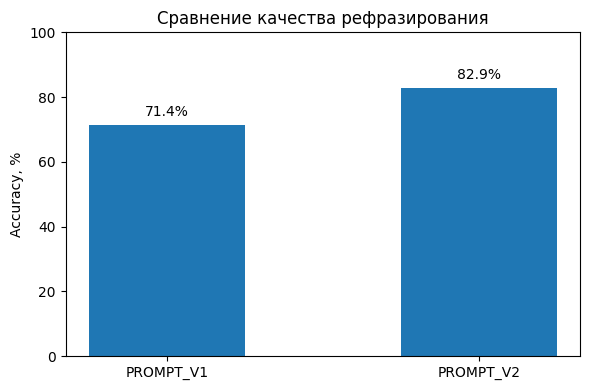

In [53]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    summary["Промпт"],
    summary["Accuracy, %"],
    width=0.5
)

ax.set_ylim(0, 100)
ax.set_ylabel("Accuracy, %")
ax.set_title("Сравнение качества рефразирования")
ax.bar_label(bars, fmt="%.1f%%", padding=4)

plt.tight_layout()
plt.show()


In [54]:
comparison_df = (
    v1_df[
        ["id", "query", "reference", "prediction", "correct"]
    ]
    .rename(columns={
        "prediction": "prediction_v1",
        "correct": "correct_v1"
    })
    .merge(
        v2_df[
            ["id", "prediction", "correct"]
        ].rename(columns={
            "prediction": "prediction_v2",
            "correct": "correct_v2"
        }),
        on="id",
        validate="one_to_one"
    )
    .sort_values("id")
    .reset_index(drop=True)
)

# Ошибки V1, исправленные в V2
improved = comparison_df[
    (comparison_df["correct_v1"] == 0) &
    (comparison_df["correct_v2"] == 1)
]

# Новые ошибки V2
regressed = comparison_df[
    (comparison_df["correct_v1"] == 1) &
    (comparison_df["correct_v2"] == 0)
]

# Проверяем полноту сравнения
assert len(comparison_df) == 35

print(f"Исправлено ошибок: {len(improved)}")
print(f"Новых ошибок: {len(regressed)}")

print("\nID исправленных примеров:", improved["id"].tolist())
print("ID ухудшившихся примеров:", regressed["id"].tolist())


Исправлено ошибок: 6
Новых ошибок: 2

ID исправленных примеров: [3, 5, 13, 23, 31, 38]
ID ухудшившихся примеров: [34, 35]


In [55]:
columns = [
    "id",
    "query",
    "reference",
    "prediction_v1",
    "prediction_v2"
]

print("Примеры с улучшением качества:")
display(improved[columns])

print("Примеры с ухудшением качества:")
display(regressed[columns])


Примеры с улучшением качества:


,id,query,reference,prediction_v1,prediction_v2
2,3,"Не, давай которые старее 1990 года","Фильмы про пиратов, которые вышли раньше 1990 года",Фильмы про пиратов старше 1990 года,Фильмы про пиратов до 1990 года.
4,5,"Давай, которые снял Джеймс Кэмерон","Фантастические фильмы, снятые Джеймсом Кэмероном",Фантастика с Джеймсом Кэмероном,Фантастика Джеймса Кэмерона
12,13,"Теперь фильмы в таком же жанре, только про преступников",Фильмы про преступников в жанре хоррор,Фильмы про восстание преступников в жанре хоррор,Фильмы в жанре хоррор про преступников
22,23,Все фантастические фильмы,Все фантастические фильмы,Фантастические фильмы после 2010 года,Фантастические фильмы
26,31,"Из этих трёх оставь фильмы, где один и тот же день повторяется.","Фильмы из списка «День сурка», «Помни» и «Начало», в которых один и тот же день повторяется.",«День сурка»,"Фильмы из списка «День сурка», «Помни» и «Начало», где один и тот же день повторяется."
31,38,Документальные фильмы о восстановлении старых зданий.,Документальные фильмы о восстановлении старых зданий.,Документальные фильмы про реставрацию исторических зданий,Документальные фильмы о восстановлении старых зданий


Примеры с ухудшением качества:


,id,query,reference,prediction_v1,prediction_v2
28,34,"Хочется чего-то трогательного, чтобы в конце осталось тёплое чувство, а не тяжесть.","Трогательные фильмы о том, как взрослые дети заново учатся общаться с родителями, оставляющие в конце тёплое чувство, а не тяжесть.","Фильм про взрослых детей, которые преодолевают трудности в общении с родителями, с тёплым и светлым финалом",Фильм о сложных отношениях взрослых детей и родителей с тёплым финалом.
29,35,"Не длиннее двух часов, завтра всем рано вставать.","Фильмы с запутанным сюжетом для внимательного просмотра с друзьями вечером и последующего обсуждения, продолжительностью не больше двух часов.",Фильм с запутанным сюжетом длительностью не больше двух часов для обсуждения с друзьями,Фильм с запутанным сюжетом длительностью не дольше двух часов



**Результаты сравнения**

Улучшенный промпт `PROMPT_V2` показал Accuracy **82.9%** против **71.4%** у исходного `PROMPT_V1`. Абсолютный прирост составил **11,4 процентного пункта**.

Из 35 примеров:

- в **6 случаях** удалось исправить ошибки исходного промпта;
- в **2 случаях** появились новые ошибки;
- в **23 случаях** обе версии дали корректные ответы;
- в **4 случаях** обе версии допустили ошибки.

Наиболее значимые улучшения наблюдаются при:

- **Отмене ограничений.** Модель перестала переносить устаревшее ограничение по году.
- **Замене темы.** Улучшилось разделение сохраняемого жанра и полностью заменяемой сюжетной темы.
- **Работе с предыдущими ответами поисковой системы.** В одном из сценариев модель сформировала запрос для отбора фильмов вместо самостоятельного выполнения отбора.
- **Передаче временных условий.** Уточнение периода выпуска и ограничений по длительности стало более точным в отдельных примерах.

Вместе с тем улучшенная инструкция не устранила все ошибки. В частности, модель по-прежнему может терять отрицательные ограничения, необоснованно сужать понятия и пропускать отдельные пользовательские предпочтения.

**Вывод.** Комбинация подробных правил обработки контекста, отслеживания актуальных ограничений и few-shot-примеров улучшила результаты рефразирования на разработочной выборке.

Однако полученный прирост не следует интерпретировать как доказательство устойчивого превосходства на произвольных пользовательских диалогах. Размер выборки невелик, а её примеры использовались при подборе промпта.


### 3.5. Анализ ошибок и выбор итогового промпта

По результатам экспериментов для дальнейшего использования выбран улучшенный промпт `PROMPT_V2`.

На разработочной выборке он обеспечил Accuracy **82,9% (29 из 35)** против **71,4% (25 из 35)** у базовой версии. Прирост составил **11,4 процентного пункта**.

Улучшенный промпт исправил ошибки исходной версии в шести сценариях, однако допустил две новые ошибки. В четырёх сценариях обе версии оказались некорректными.

Анализ шести оставшихся ошибок итогового промпта выявил ограничения выбранного подхода.

| ID | Тип ошибки | Описание |
|---|---|---|
| 7  | Подмена поискового ограничения (смысловое искажение). | Модель заменила условие «романтические комедии, снятые в России» на «российские романтические комедии». Место съёмок и страна производства фильма не эквивалентны, поэтому исходное ограничение было искажено. |
| 17 | Неполное разрешение контекста | Не указано явное исключение Марса при поиске фильмов о путешествиях на другие планеты. |
| 26 | Потеря ограничения | При замене документального фильма художественным потеряно условие об отсутствии кулинарных соревнований. |
| 27 | Необоснованное сужение смысла | Понятие «кто-то из близких» заменено более узким «близкий родственник». |
| 34 | Неполная передача темы | Вместо восстановления общения взрослых детей с родителями сохранено лишь общее описание сложных отношений. |
| 35 | Потеря пользовательского предпочтения | Из результата исключено пожелание найти фильм для последующего обсуждения с друзьями. |

Таким образом, основные оставшиеся ошибки связаны с неполным сохранением накопленных условий и недостаточно точной передачей пользовательских предпочтений.

Несмотря на эти ограничения, `PROMPT_V2` выбран в качестве итогового варианта, поскольку он показал наибольшую долю корректных ответов среди исследованных инструкций на разработочной выборке.

При этом разработочная выборка использовалась для подбора промпта. Поэтому полученные на ней 85,7% не являются независимой оценкой качества.

Для проверки способности рефразера работать с новыми сценариями проводится отдельный эксперимент на ранее отложенной тестовой выборке.



#### Проверка на отложенной тестовой выборке

После выбора итогового промпта проведена дополнительная проверка на 10 диалоговых сценариях, не использовавшихся при настройке системной инструкции.

Для генерации применялись те же модель `GigaChat-2`, температура `0.1` и формат входных данных.

Промпт перед проведением теста был зафиксирован. Результаты тестовой выборки не используются для его дальнейшей корректировки.

Ниже представлены ответы итогового рефразера.

In [56]:
test_results = load_results("results_v2_test.json")

test_df = (
    pd.DataFrame(test_results)
    .sort_values("id")
    .reset_index(drop=True)
)

assert len(test_df) == 10
assert set(test_df["id"]) == TEST_IDS

display(
    test_df[["id", "query", "reference", "prediction"]]
)


,id,query,reference,prediction
0,24,И обязательно на основе реальных событий.,"Фильмы, основанные на реальных событиях, о совместном выживании группы людей зимой в изоляции от цивилизации.","Фильм про людей, оказавшихся отрезанными от цивилизации зимой, выживающих вместе и основанный на реальных событиях."
1,25,Грустные сцены всё-таки можно.,Полнометражные мультфильмы про дружбу человека и животного для просмотра с ребёнком шести лет.,"Полнометражный мультфильм про дружбу человека и животного с грустными сценами, подходящий для ребёнка шести лет."
2,28,"Есть ещё? Всё, что ты перечислил, уже видели.","Мультфильмы про отношения в семье, кроме мультфильмов «Тайна Коко», «Энканто» и «Митчеллы против машин».","Мультики про отношения в семье, кроме «Тайны Коко», «Энканто» и «Митчелов против машин»."
3,30,Какие фильмы похожи на твою рекомендацию?,"Фильмы про необычную дружбу, похожие на «1+1», без мрачного финала.",Фильмы про необычную дружбу с счастливым концом
4,33,"Хочу напряжённый фильм, чтобы до самого конца было непонятно, кому можно доверять.","Хочу напряжённый фильм, чтобы до самого конца было непонятно, кому можно доверять.","Напряжённые фильмы, где до конца неясно, кому можно доверять"
5,36,"Нужен полнометражный мультфильм для семейного вечера с ребёнком пяти лет, без сцен разлуки с родителями.","Нужен полнометражный мультфильм для семейного вечера с ребёнком пяти лет, без сцен разлуки с родителями.",Полнометражный семейный мультфильм без сцен разлуки с родителями для ребёнка пяти лет
6,40,Подбери музыкальные мультфильмы про подготовку к выступлению на сцене.,Подбери музыкальные мультфильмы про подготовку к выступлению на сцене.,Музыкальные мультфильмы про подготовку к выступлению на сцене
7,42,"Не только животные: люди тоже подойдут, но только не охотники в главных ролях.","Мультфильмы, в которых главные герои — животные, люди или животные вместе с людьми, но никто из главных героев не является охотником.","Мультики, где главные герои — животные или люди, но без охотников."
8,43,"Перестрелки допустимы, но без захвата детей в заложники.",Фильмы про ограбление банка без захвата детей в заложники.,"Фильмы про ограбление банка без захвата детей в заложники, но с перестрелками."
9,45,"Найди фильмы, похожие на первый по попыткам понять язык и образ мышления пришельцев, без военного противостояния. Оба названных фильма исключи.","Фильмы, похожие на «Прибытие» по попыткам понять язык и образ мышления пришельцев, с акцентом на общении, а не на космических путешествиях, без военного про...","Фильмы про общение с пришельцами, без военного конфликта, похожие на «Прибытие». Исключить «Прибытие» и «Контакт»."


In [57]:
TEST_IDS = {24, 25, 28, 30, 33, 36, 40, 42, 43, 45}

assert len(test_df) == 10
assert set(test_df["id"]) == TEST_IDS

TEST_ERRORS = {
    25: "Отмена запрета интерпретирована как требование",
    30: "Потеряна ссылка на фильм «1+1» и изменён смысл ограничения",
    42: "Расширена область действия исключения охотников",
    43: "Допустимые перестрелки превращены в обязательные",
    45: "Потеряны существенные уточнения поискового намерения"
}

test_df["correct"] = (~test_df["id"].isin(TEST_ERRORS)).astype(int)
test_df["error"] = test_df["id"].map(TEST_ERRORS)

accuracy_test = test_df["correct"].mean()

print(f"Всего примеров: {len(test_df)}")
print(f"Корректных: {test_df['correct'].sum()}")
print(f"Ошибок: {(test_df['correct'] == 0).sum()}")
print(f"Test Accuracy: {accuracy_test:.1%}")

display(
    test_df[
        ["id", "query", "reference", "prediction", "correct", "error"]
    ]
)


Всего примеров: 10
Корректных: 5
Ошибок: 5
Test Accuracy: 50.0%


,id,query,reference,prediction,correct,error
0,24,И обязательно на основе реальных событий.,"Фильмы, основанные на реальных событиях, о совместном выживании группы людей зимой в изоляции от цивилизации.","Фильм про людей, оказавшихся отрезанными от цивилизации зимой, выживающих вместе и основанный на реальных событиях.",1,NaN
1,25,Грустные сцены всё-таки можно.,Полнометражные мультфильмы про дружбу человека и животного для просмотра с ребёнком шести лет.,"Полнометражный мультфильм про дружбу человека и животного с грустными сценами, подходящий для ребёнка шести лет.",0,Отмена запрета интерпретирована как требование
2,28,"Есть ещё? Всё, что ты перечислил, уже видели.","Мультфильмы про отношения в семье, кроме мультфильмов «Тайна Коко», «Энканто» и «Митчеллы против машин».","Мультики про отношения в семье, кроме «Тайны Коко», «Энканто» и «Митчелов против машин».",1,NaN
3,30,Какие фильмы похожи на твою рекомендацию?,"Фильмы про необычную дружбу, похожие на «1+1», без мрачного финала.",Фильмы про необычную дружбу с счастливым концом,0,Потеряна ссылка на фильм «1+1» и изменён смысл ограничения
4,33,"Хочу напряжённый фильм, чтобы до самого конца было непонятно, кому можно доверять.","Хочу напряжённый фильм, чтобы до самого конца было непонятно, кому можно доверять.","Напряжённые фильмы, где до конца неясно, кому можно доверять",1,NaN
5,36,"Нужен полнометражный мультфильм для семейного вечера с ребёнком пяти лет, без сцен разлуки с родителями.","Нужен полнометражный мультфильм для семейного вечера с ребёнком пяти лет, без сцен разлуки с родителями.",Полнометражный семейный мультфильм без сцен разлуки с родителями для ребёнка пяти лет,1,NaN
6,40,Подбери музыкальные мультфильмы про подготовку к выступлению на сцене.,Подбери музыкальные мультфильмы про подготовку к выступлению на сцене.,Музыкальные мультфильмы про подготовку к выступлению на сцене,1,NaN
7,42,"Не только животные: люди тоже подойдут, но только не охотники в главных ролях.","Мультфильмы, в которых главные герои — животные, люди или животные вместе с людьми, но никто из главных героев не является охотником.","Мультики, где главные герои — животные или люди, но без охотников.",0,Расширена область действия исключения охотников
8,43,"Перестрелки допустимы, но без захвата детей в заложники.",Фильмы про ограбление банка без захвата детей в заложники.,"Фильмы про ограбление банка без захвата детей в заложники, но с перестрелками.",0,Допустимые перестрелки превращены в обязательные
9,45,"Найди фильмы, похожие на первый по попыткам понять язык и образ мышления пришельцев, без военного противостояния. Оба названных фильма исключи.","Фильмы, похожие на «Прибытие» по попыткам понять язык и образ мышления пришельцев, с акцентом на общении, а не на космических путешествиях, без военного про...","Фильмы про общение с пришельцами, без военного конфликта, похожие на «Прибытие». Исключить «Прибытие» и «Контакт».",0,Потеряны существенные уточнения поискового намерения


In [58]:
import pandas as pd

generalization_df = pd.DataFrame({
    "Выборка": ["Разработочная", "Тестовая"],
    "Количество примеров": [len(v2_df), len(test_df)],
    "Корректных": [
        int(v2_df["correct"].sum()),
        int(test_df["correct"].sum())
    ],
    "Accuracy, %": [
        round(100 * accuracy_v2, 1),
        round(100 * accuracy_test, 1)
    ]
})

display(generalization_df)

gap = 100 * (accuracy_v2 - accuracy_test)

print(f"Разница между выборками: {gap:.1f} п.п.")


,Выборка,Количество примеров,Корректных,"Accuracy, %"
0,Разработочная,35,29,82.9
1,Тестовая,10,5,50.0


Разница между выборками: 32.9 п.п.


In [59]:
rows = []

for split, frame in [
    ("Разработочная", v2_df),
    ("Тестовая", test_df)
]:
    for needed, group in frame.groupby("rewrite_needed"):
        rows.append({
            "Выборка": split,
            "Требуется рефразирование": bool(needed),
            "Всего": len(group),
            "Корректных": int(group["correct"].sum()),
            "Accuracy, %": round(
                100 * group["correct"].mean(), 1
            )
        })

context_accuracy_df = pd.DataFrame(rows)

display(context_accuracy_df)

assert int(v2_df["correct"].sum()) == 29
assert int(test_df["correct"].sum()) == 5


,Выборка,Требуется рефразирование,Всего,Корректных,"Accuracy, %"
0,Разработочная,False,7,7,100.0
1,Разработочная,True,28,22,78.6
2,Тестовая,False,3,3,100.0
3,Тестовая,True,7,2,28.6


#### Результаты проверки на отложенной выборке

Итоговый рефразер `PROMPT_V2` был проверен на 10 сценариях, не использовавшихся при подборе системной инструкции.

По принятой смысловой разметке корректно обработаны **5 из 10 примеров (Accuracy = 50,0%)**. На разработочной выборке после пересмотра спорных оценок показатель составил **82,9% (29 из 35)**.

Однако общая Accuracy объединяет два разных типа задач:

- **Запросы, требующие восстановления контекста:** 22/28 (78,6%) на dev и 2/7 (28,6%) на test.
- **Самостоятельные запросы, не требующие рефразирования:** 7/7 (100%) на dev и 3/3 (100%) на test.

Таким образом, на тестовой выборке рефразер значительно хуже справлялся именно с восстановлением контекста, тогда как самостоятельные запросы сохранил корректно.

**Анализ ошибок**

Наиболее характерными проблемами стали:

1. Превращение разрешённого свойства в обязательное требование.
2. Потеря ссылок на ранее упомянутые произведения.
3. Расширение области действия отрицательных ограничений.
4. Утрата отдельных смысловых предпочтений в длинных диалогах.

**Интерпретация результатов**

Разработочная и тестовая выборки различаются по сложности и составу. Средняя длина истории составляет 1,23 реплики на dev и 2,50 на test. В тестовой выборке больше многошаговых сценариев и сложных изменений пользовательских условий.

Поэтому снижение общей Accuracy с 82,9% до 50,0% нельзя однозначно объяснить переобучением системной инструкции: оно может быть связано как с подбором промпта под dev, так и с более высокой сложностью тестовых сценариев.

Результаты следует рассматривать как предварительные из-за небольшого размера выборки, её частично синтетического происхождения и субъективности смысловой оценки с участием ChatGPT.

**Итог**

Улучшенный промпт показал более высокую Accuracy на разработочной выборке по сравнению с базовым — 82,9% против 71,4%. Однако на отложенной выборке выявлены существенные ограничения обработки контекстно-зависимых запросов.

Далее исследуется, как рефразирование, в том числе смыслово неточное, влияет на релевантность результатов семантического поиска медиаконтента.



## 4. Оценка влияния рефразирования на качество поиска медиаконтента

В предыдущем разделе исследовалась способность языковой модели преобразовывать контекстно-зависимые реплики в самостоятельные поисковые запросы. Однако смысловая корректность рефразирования не гарантирует улучшения поисковой выдачи.

**Цель эксперимента** — оценить влияние рефразирования на релевантность найденных фильмов и мультфильмов.

Для каждого диалогового сценария сравниваются три варианта запроса:

1. **Исходный запрос** (`query`) — последняя реплика пользователя без истории диалога.
2. **Рефразированный запрос** (`prediction`) — результат итогового рефразера `PROMPT_V2`.
3. **Эталонный запрос** (`reference`) — самостоятельно сформулированный запрос из подготовленного датасета.

Эталонный запрос используется как дополнительная контрольная точка: он позволяет оценить возможности поисковой системы при наличии полной информации о поисковом намерении.

Во всех трёх случаях используются одинаковые корпус документов, модель эмбеддингов и алгоритм ранжирования.

Поисковые результаты формируются для всех 45 диалоговых сценариев. Количественная оценка релевантности проводится на 10 заранее отложенных тестовых сценариях. Разработочная выборка используется для дополнительного качественного анализа.

Основная метрика — Precision@5, доля релевантных документов среди пяти первых результатов поиска.


### 4.1. Подготовка корпуса медиаконтента

Для реализации поисковой системы используется набор данных [Movie Plots from Wikipedia in Russian](https://www.kaggle.com/datasets/maksimpotorochin/movie-plots-from-wikipedia-in-russian), содержащий русскоязычные сведения о произведениях, собранные из Википедии.

Исходная таблица включает следующие поля:

| Поле | Содержание |
|---|---|
| `title` | Название произведения |
| `type` | Тип медиаконтента |
| `genre` | Жанр |
| `imdb_rating` | Рейтинг IMDb |
| `summary` | Краткая аннотация |
| `plot` | Описание сюжета |

Для поиска используются название, тип, жанр, аннотация и сюжет. Рейтинг IMDb в построении поискового представления не участвует, поскольку он не характеризует тематическую релевантность произведения пользовательскому запросу.

Подготовка корпуса включает фильтрацию типов медиаконтента, обработку пропущенных значений и удаление точных дубликатов.

В отличие от первоначального поискового эксперимента, при построении документов будут использоваться **и аннотация, и сюжет**, если соответствующие поля заполнены.

Длина текстов будет дополнительно ограничиваться с учётом максимального количества токенов, принимаемых моделью эмбеддингов.


In [60]:
%pip -q install kagglehub sentence-transformers

import hashlib
from pathlib import Path

import kagglehub
import pandas as pd

DATASET_NAME = (
    "maksimpotorochin/"
    "movie-plots-from-wikipedia-in-russian"
)

# Загрузка корпуса из Kaggle
dataset_path = Path(
    kagglehub.dataset_download(DATASET_NAME)
)

csv_files = list(
    dataset_path.rglob("films_data.csv")
)

assert len(csv_files) == 1

csv_path = csv_files[0]

# Фиксируем контрольную сумму исходного файла
sha256 = hashlib.sha256()

with csv_path.open("rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha256.update(chunk)

DATASET_SHA256 = sha256.hexdigest()


EXPECTED_DATASET_SHA256 = (
    "b74c9e20a057dc436693dc044674564ba51c04d7465662762d471cd45df80011"
)

assert DATASET_SHA256 == EXPECTED_DATASET_SHA256, (
    "Исходный корпус изменился. "
    "Результаты поиска и разметка могут быть несовместимы."
)


# Читаем CSV
films_raw = pd.read_csv(
    csv_path,
    low_memory=False
)

required_columns = {
    "title", "type", "genre",
    "summary", "plot"
}

assert required_columns.issubset(films_raw.columns)

print("Исходных записей:", len(films_raw))
print("Столбцы:", films_raw.columns.tolist())
print("SHA-256:", DATASET_SHA256)

print("\nРаспределение типов:")
display(films_raw["type"].value_counts(dropna=False))

print("\nПропущенные значения:")
display(films_raw.isna().sum())

Using Colab cache for faster access to the 'movie-plots-from-wikipedia-in-russian' dataset.
Исходных записей: 45812
Столбцы: ['title', 'type', 'genre', 'imdb_rating', 'summary', 'plot']
SHA-256: b74c9e20a057dc436693dc044674564ba51c04d7465662762d471cd45df80011

Распределение типов:


,count
type,
film,33703
tv series,4224
animated film,4059
animated series,2664
tv film,1162



Пропущенные значения:


,0
title,0
type,0
genre,812
imdb_rating,5617
summary,0
plot,3857


In [61]:
CORPUS_TYPES = {
    "film",
    "animated film",
    "tv film"
}

text_columns = [
    "title",
    "type",
    "genre",
    "summary",
    "plot"
]

corpus_df = films_raw.copy()

# Пропуски заменяем пустыми строками,
# а текстовые поля приводим к единому формату
for column in text_columns:
    corpus_df[column] = (
        corpus_df[column]
        .fillna("")
        .astype(str)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

corpus_df["type"] = corpus_df["type"].str.lower()

# Фильтруем типы медиаконтента
corpus_df = corpus_df[
    corpus_df["type"].isin(CORPUS_TYPES)
].copy()

# Убираем записи без названия
# и без содержательного текстового описания
corpus_df = corpus_df[
    (corpus_df["title"] != "") &
    (
        (corpus_df["summary"].str.len() >= 30) |
        (corpus_df["plot"].str.len() >= 30)
    )
].copy()

# Удаляем точные дубликаты
corpus_df = corpus_df.drop_duplicates(
    subset=[
        "title", "type", "genre",
        "summary", "plot"
    ]
).reset_index(drop=True)

# Фиксируем позиции документов в текущем корпусе
corpus_df["corpus_id"] = corpus_df.index

print("Документов после очистки:", len(corpus_df))

print("\nТипы документов:")
display(corpus_df["type"].value_counts())

print("\nПолнота текстовых данных:")
print(
    "С аннотацией:",
    (corpus_df["summary"] != "").sum()
)
print(
    "С сюжетом:",
    (corpus_df["plot"] != "").sum()
)
print(
    "С обоими полями:",
    (
        (corpus_df["summary"] != "") &
        (corpus_df["plot"] != "")
    ).sum()
)


Документов после очистки: 38923

Типы документов:


,count
type,
film,33703
animated film,4058
tv film,1162



Полнота текстовых данных:
С аннотацией: 38923
С сюжетом: 36629
С обоими полями: 36629


In [62]:
corpus_df["summary_length"] = (
    corpus_df["summary"].str.len()
)

corpus_df["plot_length"] = (
    corpus_df["plot"].str.len()
)

print("Длина аннотаций (символы):")
display(
    corpus_df["summary_length"].describe(
        percentiles=[0.5, 0.9, 0.95]
    )
)

print("\nДлина сюжетов (символы):")
display(
    corpus_df["plot_length"].describe(
        percentiles=[0.5, 0.9, 0.95]
    )
)

print("\nПримеры содержательных описаний:")

examples = corpus_df[
    corpus_df["plot_length"] >= 300
].sample(n=3, random_state=42)

for _, movie in examples.iterrows():
    print("\n" + "=" * 65)
    print("Название:", movie["title"])
    print("Жанр:", movie["genre"])
    print("Аннотация:", movie["summary"][:300])
    print("Сюжет:", movie["plot"][:500])


Длина аннотаций (символы):


,summary_length
count,38923.000000
mean,338.259975
std,323.021832
min,19.000000
50%,241.000000
90%,667.000000
95%,942.900000
max,6510.000000



Длина сюжетов (символы):


,plot_length
count,38923.000000
mean,1423.121856
std,1851.742439
min,0.000000
50%,722.000000
90%,3658.000000
95%,5086.700000
max,26414.000000



Примеры содержательных описаний:

Название: Посторонние
Жанр: драма криминальный фильм
Аннотация: «Посторонние» (фр. Bande à part), иногда в прокате «Банда аутсайдеров» — драма-нуар Жана-Люка Годара по произведению Долорес Хитченс «Золото дураков» (англ. Fools' Gold), впервые изданному в pulp-журнале. Один из характерных фильмов французской «новой волны». Годар сказал об этом фильме: «Алиса в ст
Сюжет: Одиль знакомится с двумя молодыми людьми, Артуром и Францем, на курсах английского языка. Девушка рассказывает Францу о куче денег, спрятанной на вилле, где она живёт со своей тетёй Викторией и её супругом Штольцем в пригороде Парижа. Франц делится этой информацией с Артуром, и они вместе убеждают Одиль принять участие в ограблении. При этом девушка влюбляется в Артура и грезит о светлом будущем рядом с ним. Неожиданно в дело вклинивается дядя Артура, который решает присвоить часть денег себе. М

Название: Розовая пантера наносит новый удар
Жанр: комедия
Аннотация: «Розовая пантера нано


### 4.2. Реализация семантического поиска

Для поиска медиаконтента используется предварительно обученная модель `intfloat/multilingual-e5-small`, формирующая векторные представления текстов размерности 384.

Модель выбрана благодаря поддержке русского языка, сравнительно небольшому размеру и возможности выполнять семантический поиск без дополнительного обучения.

Максимальная длина входного текста составляет 512 токенов. Поскольку описания сюжетов могут значительно превышать этот предел, для каждого документа формируется сокращённое представление.

При подготовке поискового текста используется следующий порядок:

1. Сохраняются название, тип и жанр произведения.
2. Включается аннотация, ограниченная 96 токенами.
3. Оставшееся пространство используется для начала описания сюжета.
4. Итоговый текст обрезается по токенам, с резервом для служебных токенов модели.

Таким образом, в отличие от первоначальной реализации, поисковая модель получает информацию не только из краткой аннотации, но и из сюжета.

Для документов используется префикс `passage:`, а для запросов — `query:`, в соответствии с рекомендациями разработчиков модели.

Все документы индексируются одним и тем же способом. Модель эмбеддингов и параметры поиска остаются фиксированными на протяжении эксперимента.


In [63]:
import torch
from sentence_transformers import SentenceTransformer

MODEL_NAME = "intfloat/multilingual-e5-small"

device = "cuda" if torch.cuda.is_available() else "cpu"

search_model = SentenceTransformer(
    MODEL_NAME,
    device=device
)

tokenizer = search_model.tokenizer

MAX_LENGTH = search_model.max_seq_length

print("Устройство:", device)
print("Модель:", MODEL_NAME)
print("Максимум токенов:", MAX_LENGTH)
print("Размерность эмбеддингов:",
      search_model.get_sentence_embedding_dimension())


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

...

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

Устройство: cuda
Модель: intfloat/multilingual-e5-small
Максимум токенов: 512
Размерность эмбеддингов: 384


/tmp/ipykernel_1943/2743330342.py:21: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  search_model.get_sentence_embedding_dimension())


In [64]:
# Оставляем небольшой резерв для служебных токенов
DOCUMENT_TOKEN_BUDGET = MAX_LENGTH - 12

# Максимальное количество токенов аннотации
SUMMARY_TOKEN_BUDGET = 96


def truncate_tokens(text: str, max_tokens: int) -> str:
    """Обрезает текст до заданного числа токенов."""

    token_ids = tokenizer.encode(
        text,
        add_special_tokens=False,
        truncation=True,
        max_length=max_tokens
    )

    return tokenizer.decode(
        token_ids,
        skip_special_tokens=True
    ).strip()


def build_document(row):
    # Аннотация занимает ограниченную часть документа
    summary = truncate_tokens(
        row["summary"],
        SUMMARY_TOKEN_BUDGET
    )

    # Собираем документ, добавляя сюжет после аннотации
    document = (
        f"passage: "
        f"Название: {row['title']}. "
        f"Тип: {row['type']}. "
        f"Жанр: {row['genre']}. "
        f"Аннотация: {summary}. "
        f"Сюжет: {row['plot']}"
    )

    # Оставляем начало текста в пределах бюджета модели
    document = truncate_tokens(
        document,
        DOCUMENT_TOKEN_BUDGET
    )

    return document


corpus_df["document"] = corpus_df.apply(
    build_document,
    axis=1
)

print("Подготовлено документов:", len(corpus_df))


Подготовлено документов: 38923


In [65]:
# Измеряем длины уже сформированных документов
token_lengths = corpus_df["document"].map(
    lambda text: len(
        tokenizer.encode(
            text,
            add_special_tokens=True
        )
    )
)

print("Максимальная длина:", token_lengths.max())
print("Средняя длина:", round(token_lengths.mean(), 1))
print("Медианная длина:", token_lengths.median())

assert token_lengths.max() <= MAX_LENGTH, (
    "Некоторые документы превышают предел модели!"
)

print("\nВсе документы укладываются в окно модели.")

# Рассматриваем несколько подготовленных текстов
for _, movie in corpus_df.sample(
    n=3,
    random_state=42
).iterrows():
    print("\n" + "=" * 70)
    print("Название:", movie["title"])
    print("Документ:")
    print(movie["document"][:1200])


Максимальная длина: 502
Средняя длина: 325.5
Медианная длина: 303.0

Все документы укладываются в окно модели.

Название: Свадебный подарок (фильм)
Документ:
passage: Название: Свадебный подарок (фильм). Тип: film. Жанр: комедия мелодрама. Аннотация: «Сва́дебный пода́рок» — советский художественный фильм-комедия, созданный в 1982 году режиссёрами Роланом Быковым, Резо Эсадзе и Александром Игишевым на Одесской киностудии.. Сюжет: Юрий, уезжая на два года в Африку, оставил своему младшему брату, собирающемуся жениться, ключи от своей квартиры, чтобы супруги жили там в его отсутствие. Молодожёны уединяются, чтобы насладиться первой брачной ночью, но неожиданно выясняется, что уехавший брат мужа — человек очень коммуникабельный, а потому многие его друзья имеют ключи от его квартиры...

Название: Грязные дневники
Документ:
passage: Название: Грязные дневники. Тип: film. Жанр: Порнография Артхаус. Аннотация: «Грязные дневники» (англ. Dirty Diaries) — шведский порнографический фильм, который

In [66]:
# Все подготовленные поисковые документы
passages = corpus_df["document"].tolist()

# Преобразуем документы в векторы
corpus_embeddings = search_model.encode(
    passages,
    batch_size=64 if device == "cuda" else 16,
    show_progress_bar=True,
    convert_to_tensor=True,
    normalize_embeddings=True
)

# Проверяем результат
assert corpus_embeddings.shape == (
    len(corpus_df),
    384
)

assert torch.isfinite(corpus_embeddings).all().item()

print("Размерность матрицы:", corpus_embeddings.shape)
print("Устройство:", corpus_embeddings.device)
print("Тип данных:", corpus_embeddings.dtype)


Batches:   0%|          | 0/609 [00:00<?, ?it/s]

Размерность матрицы: torch.Size([38923, 384])
Устройство: cuda:0
Тип данных: torch.float32



#### Ранжирование поисковых результатов

После построения эмбеддингов поиск выполняется без повторного кодирования корпуса.

Поступивший запрос преобразуется моделью `multilingual-e5-small` в вектор размерности 384. Для запроса используется префикс `query:`, а для документов ранее использовался префикс `passage:`.

Близость запроса \(q\) и документа \(d\) оценивается с помощью косинусного сходства:

$$
\operatorname{sim}(q,d) =
\frac{q \cdot d}{\|q\| \|d\|}
$$

Поскольку эмбеддинги заранее нормированы, вычисление сводится к скалярному произведению векторов.

Для поиска пяти наиболее близких документов используется операция `torch.topk()`. Результаты сортируются по убыванию сходства.

Значение сходства не является вероятностью релевантности: соответствие найденных фильмов пользовательскому намерению оценивается отдельно.


In [67]:
def search_movies(query: str, top_k: int = 5) -> pd.DataFrame:
    """Поиск наиболее близких документов по эмбеддингам."""

    # Преобразуем поисковый запрос в вектор
    query_embedding = search_model.encode(
        "query: " + query,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    # Используем то же устройство, что и матрица фильмов
    query_embedding = query_embedding.to(
        corpus_embeddings.device
    )

    # Вычисляем сходство запроса со всеми документами
    scores = corpus_embeddings @ query_embedding

    # Получаем top_k наиболее близких документов
    values, indices = torch.topk(
        scores,
        k=min(top_k, len(corpus_df))
    )

    results = []

    for rank, (score, idx) in enumerate(
        zip(values.tolist(), indices.tolist()),
        start=1
    ):
        movie = corpus_df.iloc[idx]

        results.append({
            "rank": rank,
            "corpus_id": int(movie["corpus_id"]),
            "title": movie["title"],
            "type": movie["type"],
            "genre": movie["genre"],
            "score": round(score, 4),
            "summary": movie["summary"][:350]
        })

    return pd.DataFrame(results)


In [68]:
# Объединяем результаты разработочной и тестовой выборок
examples_df = pd.concat(
    [v2_df, test_df],
    ignore_index=True
).set_index("id")

assert len(examples_df) == 45
assert examples_df.index.is_unique


def show_search_example(example_id: int):
    example = examples_df.loc[example_id]

    variants = {
        "Исходный запрос": example["query"],
        "Рефразированный запрос": example["prediction"],
        "Эталонный запрос": example["reference"]
    }

    print(f"СЦЕНАРИЙ №{example_id}")

    for name, query in variants.items():
        print(f"\n{name}: {query}")

        display(
            search_movies(query)[
                ["rank", "title", "genre", "score", "summary"]
            ]
        )


show_search_example(2)


СЦЕНАРИЙ №2

Исходный запрос: А из девяностых?


,rank,title,genre,score,summary
0,1,Когда тебе семнадцать,кинодрама,0.8478,"Когда тебе семнадцать (фр. Quand on a 17 ans) — французский драматический фильм, снятый Андре Тешине. Мировая премьера ленты состоялась в феврале 2016 года ..."
1,2,"Девять жизней (фильм, 2005)",драма,0.8419,«Девять жизней» (англ. Nine Lives) — американская драма 2005 года режиссёра Родриго Гарсиа. Премьера состоялась 24 января 2005 года на кинофестивале Сандэнс.
2,3,"Десять (фильм, 2002)",драма,0.8327,«Десять» (перс. ده‎‎) — художественный фильм иранского режиссёра Аббаса Киаростами 2002 года.
3,4,Папе снова 17,комедия,0.8323,"«Папе снова 17» (англ. 17 Again, 2009) — американская кинокомедия режиссёра Бёрра Стирса о попытке исправить ошибки молодости. Слоган фильма: «Who says you’..."
4,5,"Семнадцатилетние (фильм, 2002)",комедия мелодрама драма романтика,0.8322,Семнадцатилетние (англ. Try Seventeen также имеет название англ. All I Want) — романтическая комедия о студенческой любви.



Рефразированный запрос: Фильмы про путешествия во времени из девяностых годов.


,rank,title,genre,score,summary
0,1,Путешествие времени,документальный фильм и драматический фильм,0.8470,"«Путешествие времени» (англ. Voyage of Time) — американский документальный фильм, снятый Терренсом Маликом. Мировая премьера ленты состоялась 7 сентября 201..."
1,2,Жизнь в чемоданах,драма приключения,0.8465,"«Жизнь в чемоданах» (англ. A Life in Suitcases: A History of Tulse Luper) — полнометражный фильм Питера Гринуэя, в котором кратко пересказываются показанные..."
2,3,Путешествие к седьмой планете,фантастика,0.8444,"«Путешествие к седьмой планете» (англ. Journey To The Seventh Planet) — фильм режиссёра Сиднея Пинка, снятый в жанре фантастики. Совместное производство Дан..."
3,4,Путешествие вдвоём,драма,0.8384,«Путешествие вдвоём» (фр. Le Voyage en douce) — драма 1980 года. Фильм был номинирован на главный приз 30-го «Берлинского кинофестиваля».
4,5,Какое отношение мы имеем к революции?,комедия драма,0.8382,"«При чём здесь мы, когда кругом революция!?» (итал. Che C ` entriamo Noi Con La Rivoluzione?; исп. Que Nos Importa La Revolucion!; англ. What Am I Doing In ..."



Эталонный запрос: Фильмы про путешествия во времени из 90-х


,rank,title,genre,score,summary
0,1,Середина 90-х,комедиядрама,0.8643,"«Середина 90-х» (англ. Mid90s) — американский комедийно-драматический фильм, написанный и срежиссированный Джоной Хиллом и являющийся его режиссёрским дебют..."
1,2,"Путешествие (фильм, 1993)",Триллер,0.8598,"«Путеше́ствие» (англ. Voyage) — фильм 1993 года, триллер, главные роли в котором исполнили Эрик Робертс, Рутгер Хауэр и Карен Аллен."
2,3,Жизнь в чемоданах,драма приключения,0.8561,"«Жизнь в чемоданах» (англ. A Life in Suitcases: A History of Tulse Luper) — полнометражный фильм Питера Гринуэя, в котором кратко пересказываются показанные..."
3,4,Путешествие времени,документальный фильм и драматический фильм,0.8513,"«Путешествие времени» (англ. Voyage of Time) — американский документальный фильм, снятый Терренсом Маликом. Мировая премьера ленты состоялась 7 сентября 201..."
4,5,"Младенец на прогулке, или Ползком от гангстеров",комедия приключенческий фильм семейный фильм криминальный фильм,0.8512,"«Младенец на прогулке, или Ползком от гангстеров» (англ. Baby's Day Out) — американская приключенческая комедия 1994 года режиссёра Патрика Рида Джонсона. П..."



### 4.3. Постановка и проведение поискового эксперимента

Для оценки влияния рефразирования на поиск проводится сравнение трёх вариантов запросов:

- **Original** — исходная реплика пользователя без истории диалога.
- **Rewritten** — результат итогового рефразера `PROMPT_V2`.
- **Reference** — эталонная самостоятельная формулировка запроса.

Каждый запрос передаётся в семантический поисковик независимо от остальных. Во всех экспериментах используются одинаковый корпус, модель `intfloat/multilingual-e5-small`, косинусное сходство и `Top-5` результатов.

Всего рассматриваются 45 диалоговых сценариев, для которых формируются 135 поисковых выдач.

Для итоговой количественной оценки используются 10 заранее отложенных тестовых сценариев. Остальные сценарии могут применяться для качественной иллюстрации результатов.

Эталонный запрос выступает дополнительным контрольным вариантом, но не гарантирует максимальную релевантность выдачи: поисковая модель может ошибаться даже при полностью сформулированном запросе.

Поисковые результаты сохраняются отдельно для дальнейшей оценки без повторного вычисления эмбеддингов.


In [69]:
import json
from pathlib import Path

TOP_K = 5

VARIANTS = {
    "original": "query",
    "rewritten": "prediction",
    "reference": "reference"
}

assert len(examples_df) == 45
assert examples_df.index.is_unique
assert set(VARIANTS.values()).issubset(examples_df.columns)

retrieval_results = []

for example_id, example in examples_df.sort_index().iterrows():
    searches = {}

    for variant, column in VARIANTS.items():
        query = str(example[column]).strip()
        assert query

        found = search_movies(query, top_k=TOP_K)

        searches[variant] = {
            "query": query,
            "top5": found.to_dict("records")
        }

    retrieval_results.append({
        "id": int(example_id),
        "searches": searches
    })

# Проверяем полноту полученных результатов
assert len(retrieval_results) == 45
assert all(
    len(item["searches"][variant]["top5"]) == TOP_K
    for item in retrieval_results
    for variant in VARIANTS
)

# Сохраняем параметры эксперимента вместе с выдачей
retrieval_artifact = {
    "config": {
        "model": MODEL_NAME,
        "dataset_sha256": DATASET_SHA256,
        "corpus_size": len(corpus_df),
        "max_seq_length": MAX_LENGTH,
        "summary_token_budget": SUMMARY_TOKEN_BUDGET,
        "document_token_budget": DOCUMENT_TOKEN_BUDGET,
        "top_k": TOP_K,
        "similarity": "cosine"
    },
    "results": retrieval_results
}

output_path = Path("retrieval_top5_v2.json")

output_path.write_text(
    json.dumps(
        retrieval_artifact,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("Сценариев:", len(retrieval_results))
print("Поисковых выдач:", len(retrieval_results) * 3)
print("Поисковых позиций:", len(retrieval_results) * 3 * TOP_K)
print("Сохранено в:", output_path)


Сценариев: 45
Поисковых выдач: 135
Поисковых позиций: 675
Сохранено в: retrieval_top5_v2.json


In [70]:
def show_retrieval_comparison(example_id: int):
    example = next(
        item for item in retrieval_results
        if item["id"] == example_id
    )

    print(f"СЦЕНАРИЙ №{example_id}")

    for variant, data in example["searches"].items():
        print(f"\n{variant}: {data['query']}")

        display(
            pd.DataFrame(data["top5"])[
                ["rank", "title", "genre", "score"]
            ]
        )


show_retrieval_comparison(13)


СЦЕНАРИЙ №13

original: Теперь фильмы в таком же жанре, только про преступников


,rank,title,genre,score
0,1,"Такой же предатель, как и мы",шпионский триллер,0.8385
1,2,Преступники в ночи,криминальный фильм триллер боевик,0.8338
2,3,Мошенники как и мы,комедия,0.8338
3,4,А теперь нечто совсем другое,комедия,0.8332
4,5,Они живут по ночам,нуарmwparseroutput tsfixtemplatewhitespacenowrapmwparseroutput tsfixerrorfontsizeinheritmedia screenmwparseroutput tsfixtextborderpx solid aabboxdecorationb...,0.8327



rewritten: Фильмы в жанре хоррор про преступников


,rank,title,genre,score
0,1,Преступники в ночи,криминальный фильм триллер боевик,0.8753
1,2,Ключ от преисподней,фильм ужасов,0.8704
2,3,Преступления и проступки,драма комедия,0.8685
3,4,Пропащие ребята 3: Жажда,боевик приключенческий фильм комедия фильм ужасов триллер,0.8666
4,5,"Пророк (фильм, 2009)",драма криминальный фильм,0.8655



reference: Фильмы про преступников в жанре хоррор


,rank,title,genre,score
0,1,Преступники в ночи,криминальный фильм триллер боевик,0.8759
1,2,Ключ от преисподней,фильм ужасов,0.8681
2,3,Преступления и проступки,драма комедия,0.8679
3,4,Пропащие ребята 3: Жажда,боевик приключенческий фильм комедия фильм ужасов триллер,0.8653
4,5,"Преступник (фильм, 2008)",триллер драма,0.8653



### 4.4. Оценка релевантности поисковой выдачи

Для количественного сравнения поисковых результатов необходимо определить, насколько найденные фильмы и мультфильмы соответствуют актуальному намерению пользователя.

Оценивание проводится на десяти заранее отложенных тестовых сценариях. Для каждого сценария объединяются результаты трёх поисковых выдач: Original, Rewritten и Reference.

Повторяющиеся произведения с одинаковым идентификатором корпуса в пределах одного сценария оцениваются один раз.

При определении релевантности используются исходная история диалога, эталонный запрос, название, тип, жанр, аннотация и описание сюжета найденного произведения.

Используется следующая шкала:

- **1 — релевантен:** доступные сведения подтверждают соответствие актуальным поисковым требованиям.
- **0 — нерелевантен:** обнаружено противоречие существенному требованию пользователя.
- **? — недостаточно информации:** по доступным сведениям невозможно уверенно установить соответствие всем существенным требованиям.

Оценка определяется без информации о том, по какому варианту запроса найден документ. Это позволяет применять одинаковые критерии ко всем трём экспериментальным условиям.

Разметка проводится с помощью ChatGPT и впоследствии рассматривается как предварительная модельная оценка, а не независимая экспертная разметка.


In [71]:
import json
from pathlib import Path

TEST_IDS = set(test_df["id"])

test_lookup = test_df.set_index("id")

annotation_scenarios = []

for result in retrieval_results:
    example_id = result["id"]

    if example_id not in TEST_IDS:
        continue

    example = test_lookup.loc[example_id]
    unique_movies = {}

    # Объединяем кандидатов из трёх выдач
    for variant in ["original", "rewritten", "reference"]:
        hits = result["searches"][variant]["top5"]

        for hit in hits:
            corpus_id = int(hit["corpus_id"])

            if corpus_id in unique_movies:
                continue

            movie = corpus_df.iloc[corpus_id]

            assert int(movie["corpus_id"]) == corpus_id

            unique_movies[corpus_id] = {
                "corpus_id": corpus_id,
                "title": movie["title"],
                "type": movie["type"],
                "genre": movie["genre"],
                "summary": movie["summary"],
                "plot": movie["plot"]
            }

    annotation_scenarios.append({
        "id": int(example_id),
        "history": example["history"],
        "query": example["query"],
        "reference": example["reference"],
        "candidates": list(unique_movies.values())
    })

annotation_scenarios.sort(key=lambda x: x["id"])

# Контроль полноты
assert len(annotation_scenarios) == 10
assert {s["id"] for s in annotation_scenarios} == TEST_IDS

total_candidates = sum(
    len(s["candidates"])
    for s in annotation_scenarios
)

print("Тестовых сценариев:", len(annotation_scenarios))
print("Уникальных пар сценарий–фильм:", total_candidates)

# Сохраняем входные данные для оценивания
annotation_data = {
    "dataset_sha256": DATASET_SHA256,
    "scenarios": annotation_scenarios
}

annotation_path = Path("retrieval_candidates_test_v2.json")

annotation_path.write_text(
    json.dumps(
        annotation_data,
        ensure_ascii=False,
        indent=2
    ),
    encoding="utf-8"
)

print("Файл сохранён:", annotation_path)


Тестовых сценариев: 10
Уникальных пар сценарий–фильм: 101
Файл сохранён: retrieval_candidates_test_v2.json


In [72]:
import requests
import pandas as pd

LABELS_URL = (
    "https://raw.githubusercontent.com/"
    "Relock203/media-content-query-rewriting/"
    "main/retrieval_labels_test_v2.json"
)

response = requests.get(LABELS_URL, timeout=30)
response.raise_for_status()
labels = response.json()

# Проверяем, что размечены все кандидаты
expected_keys = {
    f"{scenario['id']}:{film['corpus_id']}"
    for scenario in annotation_scenarios
    for film in scenario["candidates"]
}

assert set(labels) == expected_keys
assert set(labels.values()) <= {"0", "1", "?"}

print("Разметка проверена:", len(labels), "оценок")

# Рассчитываем Precision@5 для трёх типов запросов
metrics = []

for result in retrieval_results:
    if result["id"] not in TEST_IDS:
        continue

    for variant in ["original", "rewritten", "reference"]:
        hits = result["searches"][variant]["top5"]

        marks = [
            labels[f"{result['id']}:{hit['corpus_id']}"]
            for hit in hits
        ]

        relevant = marks.count("1")
        unknown = marks.count("?")

        metrics.append({
            "id": result["id"],
            "variant": variant,
            "relevant": relevant,
            "unknown": unknown,
            "p5_min": relevant / 5,
            "p5_max": (relevant + unknown) / 5
        })

metrics_df = pd.DataFrame(metrics)

assert len(metrics_df) == 30

summary = (
    metrics_df.groupby("variant")
    .agg(
        relevant=("relevant", "sum"),
        unknown=("unknown", "sum"),
        precision_min=("p5_min", "mean"),
        precision_max=("p5_max", "mean")
    )
    .round(3)
)

display(summary)


Разметка проверена: 101 оценок


,relevant,unknown,precision_min,precision_max
variant,,,,
original,2,1,0.04,0.06
reference,6,7,0.12,0.26
rewritten,10,10,0.20,0.40



### 4.5. Анализ результатов поискового эксперимента

По результатам поиска на 10 тестовых сценариях была рассчитана средняя Precision@5 для трёх вариантов запросов: исходного, рефразированного и эталонного.

Всего оценён 101 уникальный кандидат. Для каждого варианта запроса учитываются 50 поисковых позиций: по пять результатов на каждый из десяти сценариев.

В качестве основной оценки используется нижняя граница Precision@5, при которой документы с неопределённой релевантностью не считаются релевантными.

Для отражения недостатка информации также рассчитывается верхняя граница, предполагающая релевантность всех неопределённых документов.

Для одного сценария:

$$
P@5_{\min} = \frac{R}{5}
$$

$$
P@5_{\max} = \frac{R+U}{5}
$$

где:

- \(R\) — число подтверждённо релевантных документов;
- \(U\) — число документов с неопределённой релевантностью.

Среднее значение вычисляется по десяти сценариям.

Полученные интервалы отражают неопределённость разметки и не являются статистическими доверительными интервалами.


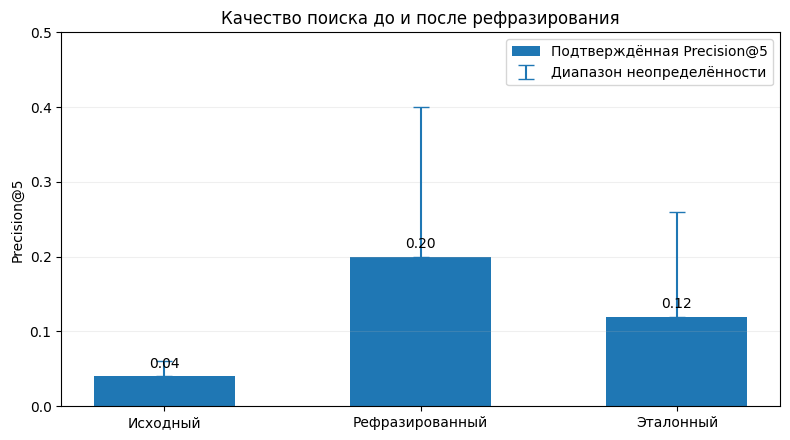

In [73]:
import matplotlib.pyplot as plt
import numpy as np

variant_order = ["original", "rewritten", "reference"]

plot_data = summary.loc[variant_order]

names = [
    "Исходный",
    "Рефразированный",
    "Эталонный"
]

lower = plot_data["precision_min"].to_numpy()
upper = plot_data["precision_max"].to_numpy()

x = np.arange(len(names))

fig, ax = plt.subplots(figsize=(8, 4.5))

bars = ax.bar(
    x,
    lower,
    width=0.55,
    label="Подтверждённая Precision@5"
)

# Показываем возможное увеличение из-за
# неопределённых документов
ax.errorbar(
    x,
    lower,
    yerr=[
        np.zeros(len(x)),
        upper - lower
    ],
    fmt="none",
    capsize=6,
    label="Диапазон неопределённости"
)

ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("Precision@5")
ax.set_ylim(0, 0.5)

ax.set_title(
    "Качество поиска до и после рефразирования"
)

ax.bar_label(
    bars,
    labels=[f"{v:.2f}" for v in lower],
    padding=4
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [74]:
scenario_comparison = metrics_df.pivot(
    index="id",
    columns="variant",
    values="p5_min"
)[["original", "rewritten", "reference"]].copy()

scenario_comparison["delta"] = (
    scenario_comparison["rewritten"] -
    scenario_comparison["original"]
)

display(
    scenario_comparison.style.format("{:.2f}")
)

improved_count = int(
    (scenario_comparison["delta"] > 0).sum()
)

unchanged_count = int(
    (scenario_comparison["delta"] == 0).sum()
)

worsened_count = int(
    (scenario_comparison["delta"] < 0).sum()
)

print("Улучшение:", improved_count)
print("Без изменений:", unchanged_count)
print("Ухудшение:", worsened_count)

print(
    "Средний прирост Precision@5:",
    round(scenario_comparison["delta"].mean(), 3)
)


variant,original,rewritten,reference,delta
id,,,,
24,0.00,0.20,0.00,0.20
25,0.00,0.20,0.20,0.20
28,0.00,0.40,0.20,0.40
30,0.00,0.00,0.00,0.00
33,0.20,0.20,0.20,0.00
36,0.00,0.00,0.00,0.00
40,0.20,0.20,0.20,0.00
42,0.00,0.60,0.20,0.60
43,0.00,0.00,0.00,0.00


Улучшение: 5
Без изменений: 5
Ухудшение: 0
Средний прирост Precision@5: 0.16


In [75]:
best_id = int(
    scenario_comparison["delta"].idxmax()
)

weak_id = int(
    scenario_comparison["delta"].idxmin()
)

print("Наибольшее улучшение: сценарий", best_id)
show_retrieval_comparison(best_id)

if weak_id != best_id:
    print("\nНаименьшее улучшение: сценарий", weak_id)
    show_retrieval_comparison(weak_id)


Наибольшее улучшение: сценарий 42
СЦЕНАРИЙ №42

original: Не только животные: люди тоже подойдут, но только не охотники в главных ролях.


,rank,title,genre,score
0,1,Под маской (фильм),документальный,0.8048
1,2,Добро пожаловать в рай!,приключения,0.8012
2,3,"Животные (фильм, 2019)",драма комедия,0.8010
3,4,Особенности национальной охоты,комедия,0.8009
4,5,Не склонившие головы,криминальная драма,0.8007



rewritten: Мультики, где главные герои — животные или люди, но без охотников.


,rank,title,genre,score
0,1,Охотник и его сын,сказка,0.8567
1,2,Приключения кузнечика Кузи (история первая),музыкальная сказка,0.8518
2,3,Фантик. Первобытная сказка,сказка,0.8508
3,4,Нехочуха,фантазия комедия,0.8497
4,5,Охота (мультфильм),фантазия,0.8489



reference: Мультфильмы, в которых главные герои — животные, люди или животные вместе с людьми, но никто из главных героев не является охотником.


...

,rank,title,genre,score
0,1,Похожие,ЛГБТтематика в кино,0.8485
1,2,"Как вам это понравится (фильм, 1936)",мелодрама,0.8478
2,3,"Такой же предатель, как и мы",шпионский триллер,0.8456
3,4,Хочу как ты,комедия фантастика,0.8442
4,5,Думай как мужчина,комедия мелодрама,0.8438



rewritten: Фильмы про необычную дружбу с счастливым концом


,rank,title,genre,score
0,1,Просто вместе (фильм),драма мелодрама,0.8638
1,2,"Лучшие друзья (фильм, 2014)",комедия,0.8633
2,3,Друзья и любовники,драма,0.8588
3,4,Забавная мордашка,кинокомедия мюзикл мелодрама,0.8565
4,5,Новая подружка,драма комедия,0.8564



reference: Фильмы про необычную дружбу, похожие на «1+1», без мрачного финала.


,rank,title,genre,score
0,1,1+1 (фильм),комедийная драма баддимуви,0.8718
1,2,Друзья и любовники,драма,0.8599
2,3,Новая подружка,драма комедия,0.8575
3,4,Дружба и никакого секса?,романтическая комедия,0.8573
4,5,Быстро и без боли,драма криминальный фильм мелодрама,0.8569



#### Анализ результатов по отдельным сценариям

Для более подробного анализа было проведено попарное сравнение нижней оценки Precision@5 до и после рефразирования в каждом из десяти тестовых сценариев.

Получены следующие результаты:

- В **5 сценариях** (№24, 25, 28, 42, 45) наблюдалось улучшение качества поиска.
- В **5 сценариях** (№30, 33, 36, 40, 43) значение метрики не изменилось.
- Сценариев со снижением нижней оценки Precision@5 не обнаружено.

Наибольшее улучшение отмечено в сценарии №42: Precision@5 увеличилась с 0,00 до 0,60. В сценарии №28 показатель увеличился с 0,00 до 0,40.

В сценариях №24, 25 и 45 прирост составил 0,20.

При этом в сценариях №30, 36 и 43 оба варианта поиска имели нулевую нижнюю Precision@5. Это демонстрирует, что даже восстановление контекста не гарантирует нахождения релевантного медиаконтента.

В сценариях №33 и 40 обе версии получили одинаковую Precision@5 = 0,20, то есть рефразирование не привело к изменению числа подтверждённо релевантных результатов в первой пятёрке.

Отдельно следует отметить, что ошибки рефразера не всегда приводят к ухудшению поисковой выдачи. Даже частично восстановленный контекст может оказаться полезным для семантического поиска.

**Обобщение.** На рассматриваемой тестовой выборке рефразирование улучшило нижнюю оценку Precision@5 в половине сценариев. Средний прирост составил 0,16.

Однако результаты зависят от качества поискового корпуса, модели эмбеддингов и процедуры оценки релевантности. Отсутствие ухудшений по консервативной метрике не исключает ухудшения фактической релевантности отдельных выдач, для которых оценка осталась неопределённой.



#### Основные результаты

На десяти тестовых сценариях средняя нижняя оценка Precision@5 составила:

| Вариант запроса | Нижняя оценка | Верхняя оценка |
|---|---:|---:|
| Исходный (Original) | 0,04 | 0,06 |
| Рефразированный (Rewritten) | 0,20 | 0,40 |
| Эталонный (Reference) | 0,12 | 0,26 |

Рефразирование увеличило нижнюю оценку Precision@5 на **0,16**, то есть на 16 процентных пунктов.

По сравнению с исходными репликами рефразированные запросы позволили получить больше документов, соответствующих актуальному поисковому намерению пользователя.

Это согласуется с основной гипотезой исследования: восстановление контекста диалога помогает семантическому поисковику учитывать информацию, отсутствующую в последней реплике пользователя.

#### Интерпретация результатов

Эталонные формулировки показали меньшую нижнюю Precision@5, чем результаты рефразера. Это не означает, что эталонные запросы хуже по смыслу.

Семантический поиск основан на близости эмбеддингов, поэтому даже смыслово эквивалентные запросы могут приводить к различным результатам ранжирования. Кроме того, интервалы неопределённости эталонного и рефразированного вариантов пересекаются.

Абсолютные показатели качества остаются сравнительно низкими. Поисковик не гарантирует одновременного соблюдения всех ограничений пользователя, особенно отрицаний, исключений, требований к отдельным сюжетным событиям и характеристикам, которые не представлены в структурированных метаданных.

#### Ограничения эксперимента

1. **Небольшая тестовая выборка.** Количественная оценка проведена на десяти сценариях, поэтому результаты нельзя без дополнительной проверки обобщать на произвольные диалоги.
2. **Модельная оценка релевантности.** Разметка выполнена с помощью ChatGPT по аннотациям и сюжетам. Она может содержать ошибки и не заменяет независимую экспертную оценку.
3. **Неполнота корпуса.** Некоторые характеристики фильмов отсутствуют в данных или недостаточно подробно описаны.
4. **Ограниченная длина документов.** Для построения эмбеддингов используется сокращённый текст, поэтому некоторые важные детали полного сюжета могут быть недоступны поисковой модели.
5. **Ограничения векторного поиска.** Косинусное сходство не обеспечивает строгую проверку каждого пользовательского условия.
6. **Неопределённость оценок.** Для части результатов невозможно достоверно установить релевантность по доступным сведениям.

#### Вывод по поисковому эксперименту

В проведённом эксперименте использование рефразированных запросов повысило нижнюю оценку Precision@5 с 0,04 до 0,20.

Полученные результаты демонстрируют практическую пользу восстановления контекста диалога для поиска медиаконтента.

В то же время качество итоговой системы ограничено не только ошибками рефразера, но и возможностями поискового алгоритма. Для дальнейшего улучшения перспективно сочетание семантического поиска со структурированной фильтрацией по метаданным и дополнительной проверкой найденных документов.



## 5. Заключение

В рамках работы был разработан и исследован рефразер контекстно-зависимых запросов для поиска фильмов и мультфильмов. Основная задача заключалась в преобразовании отдельных реплик диалога в самостоятельные поисковые формулировки, сохраняющие актуальное намерение пользователя.

Исследование включало подготовку набора диалоговых сценариев, разработку рефразера на основе GigaChat-2, эксперименты с системными инструкциями, проверку смысловой корректности и оценку влияния рефразирования на качество семантического поиска.

### Основные результаты

**1. Подготовлен набор данных для исследования рефразирования.**

Сформировано 45 диалоговых сценариев, охватывающих различные операции над поисковыми требованиями: добавление и отмену ограничений, замену темы, разрешение контекстных отсылок и исключение ранее предложенных произведений.

Из них 35 примеров использовались для разработки и подбора системной инструкции, а 10 были отложены для итоговой проверки.

**2. Разработан и улучшен рефразер запросов.**

В качестве основы использовалась модель GigaChat-2 без дополнительного обучения. Улучшение выполнялось посредством промпт-инжиниринга.

Итоговая системная инструкция сочетает правила обработки диалогового контекста, отслеживание актуальных ограничений и few-shot-примеры.

На разработочной выборке доля смыслово корректных ответов увеличилась с **71,4% (25 из 35)** у базового промпта до **82,9% (29 из 35)** у улучшенного. Прирост составил **11,4 процентного пункта**.

На отложенной тестовой выборке итоговый рефразер корректно обработал **5 из 10 запросов (50,0%)**. При этом среди семи сценариев, действительно требующих восстановления контекста, корректными оказались только два ответа (28,6%). Все три самостоятельных запроса были обработаны правильно.

Различия между разработочной и тестовой выборками, включая длину истории и сложность сценариев, ограничивают возможность обобщения полученных результатов.


**3. Реализована система семантического поиска медиаконтента.**

На основе русскоязычного корпуса из **38 923 документов** построен поисковый индекс с использованием модели `intfloat/multilingual-e5-small` и PyTorch.

Для каждого произведения использовались название, тип, жанр, аннотация и доступная часть описания сюжета. Поиск выполнялся по косинусному сходству нормированных эмбеддингов размерности 384.

Система позволила сравнить выдачи для исходных, рефразированных и эталонных поисковых запросов при неизменных параметрах поиска.

**4. Проведена оценка влияния рефразирования на релевантность поиска.**

Поисковые выдачи были сформированы для всех 45 сценариев, а количественная оценка выполнена на 10 отложенных тестовых примерах.

На основе 101 уникальной пары «сценарий — фильм» была проведена оценка релевантности с помощью ChatGPT. Для неопределённых случаев рассчитывались нижняя и верхняя границы Precision@5.

Получены следующие результаты:

| Вариант запроса | Нижняя Precision@5 | Верхняя Precision@5 |
|---|---:|---:|
| Original | 0,04 | 0,06 |
| Rewritten | 0,20 | 0,40 |
| Reference | 0,12 | 0,26 |

Использование рефразированных запросов увеличило среднюю нижнюю оценку Precision@5 с **0,04 до 0,20**, то есть на **0,16**.

Улучшение наблюдалось в пяти из десяти тестовых сценариев. В остальных пяти нижняя оценка не изменилась; случаев её снижения не зафиксировано.

При этом эталонные запросы показали меньшую нижнюю оценку Precision@5, чем рефразированные. Такой результат не свидетельствует о превосходстве рефразера над эталоном: смыслово близкие формулировки могут по-разному ранжироваться векторной поисковой моделью, а интервалы неопределённости двух вариантов пересекаются.

### Проверка гипотезы

Основная гипотеза исследования заключалась в том, что восстановление диалогового контекста повышает релевантность поисковой выдачи по сравнению с использованием последней реплики пользователя без истории.

**В проведённом эксперименте гипотеза получила предварительное подтверждение:** рефразированные запросы позволили найти больше подтверждённо релевантных документов.

При этом результаты показывают, что корректность рефразирования и эффективность поиска не эквивалентны. Даже смыслово неточная переформулировка может улучшить поиск, если она восстанавливает важные тематические признаки. С другой стороны, правильный запрос не гарантирует релевантную выдачу.

### Ограничения исследования

Полученные результаты имеют ряд ограничений:

1. Набор диалоговых сценариев сравнительно мал и сформирован специально для исследования; его нельзя считать репрезентативной выборкой реальных пользовательских запросов.
2. Разработочная выборка использовалась при подборе промптов, а тестовая содержит только десять примеров.
3. Оценка смысловой корректности рефразирования проводилась вручную при участии ChatGPT, поэтому отдельные решения могут быть субъективными.
4. Релевантность поисковых результатов оценивалась с помощью ChatGPT, а не независимыми экспертами. Неопределённость части оценок ограничивает точность итоговой метрики.
5. Корпус медиаконтента содержит неполные метаданные, а длинные описания сокращаются до допустимого размера входа модели.
6. Используемый семантический поиск не обеспечивает строгого соблюдения всех пользовательских ограничений, особенно отрицаний, временных требований и исключений.

### Возможные направления развития

Перспективными направлениями дальнейшей работы являются:

- расширение датасета и независимая экспертная оценка результатов;
- улучшение обработки отрицаний, разрешений и многошаговых изменений требований;
- дополнение семантического поиска структурированной фильтрацией по году, жанру, длительности и другим характеристикам;
- применение повторного ранжирования найденных документов с проверкой соответствия отдельным ограничениям;
- исследование альтернативных моделей эмбеддингов и методов поиска на более крупной тестовой выборке.

### Итоговый вывод

Работа демонстрирует практическую применимость контекстно-зависимого рефразирования для поиска медиаконтента.

Разработанная система способна восстанавливать информацию из диалога и использовать её при поиске фильмов и мультфильмов. Эксперимент показал повышение подтверждённой релевантности поисковой выдачи при использовании рефразированных запросов.

Одновременно выявлены существенные ограничения как самого рефразера, так и семантического поисковика. Для создания надёжной прикладной системы потребуется более точная обработка пользовательских требований, расширение метаданных и дополнительная проверка качества на независимых данных.
